# Brain MRI Classification for Dementia Severity Prediction

**Module:** 7BBG1005 - AI and Machine Learning  
**Institution:** King's College London  
**Task:** Multi-class classification of brain MRI images into dementia severity categories

---

## Aims of This Notebook

Following the experimental methodology from the course workshops, this notebook implements a **progressive evaluation approach** to brain MRI classification:

1. **Experiment 1:** Baseline CNN from scratch (no augmentation) - establish baseline performance
2. **Experiment 2:** Baseline CNN with data augmentation - evaluate augmentation impact
3. **Experiment 3:** Transfer learning with ResNet50 (partial fine-tuning) - compare pre-trained features
4. **Experiment 4:** Vision Transformer (ViT-B/16) with partial fine-tuning - evaluate advanced architecture

This approach demonstrates understanding of how each technique contributes to model performance, rather than simply applying the most sophisticated model.

### Key Design Decisions

**Baseline CNN Architecture:**
- Uses **Global Average Pooling (GAP)** instead of large fully-connected layers
- This dramatically reduces parameters (~300K vs 51M) preventing memorisation
- Forces the model to learn spatially-invariant features rather than memorising pixel positions

**Transfer Learning Strategy:**
- Uses **partial fine-tuning** rather than fully frozen backbones
- Unfreezes later layers to allow domain adaptation from natural images to medical MRI
- Earlier layers (generic edge/texture detectors) remain frozen

---

## Dataset Overview

The dataset consists of brain MRI scans classified into three severity categories:

| Class | Number of Images | Percentage |
|-------|-----------------|------------|
| NoImpairment | 2,560 | 50.4% |
| MildImpairment | 1,792 | 35.3% |
| ModerateImpairment | 724 | 14.3% |
| **Total** | **5,076** | **100%** |

**Image Dimensions:** 176 × 208 pixels (height × width)

**Key Challenge:** Significant class imbalance (ratio ~3.5:1 between largest and smallest class) requires stratified sampling and weighted loss functions.

<hr style="border:1px solid black"> </hr>

## 1. Setup and Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Core Python libraries
import os
import random
import shutil
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# PyTorch - following course pattern from cnn.ipynb
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset, WeightedRandomSampler
from torchvision import transforms, datasets
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models import vit_b_16, ViT_B_16_Weights

# Stratified splitting for handling class imbalance
from sklearn.model_selection import train_test_split

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

# Evaluation metrics - following course pattern from ModelEvaluation.ipynb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    RocCurveDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay,
    classification_report,
    auc
)
from sklearn.preprocessing import label_binarize, LabelBinarizer

# Progress bar
from tqdm.notebook import tqdm

# Set matplotlib style
plt.rcParams.update({'font.size': 12})

In [ ]:
# Set random seeds for reproducibility - following course best practice
def set_seed(seed=42):
    """Set random seeds for reproducibility across all libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Check device availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA L4


<hr style="border:1px solid black"> </hr>

## 2. Configuration

In [ ]:
# ============================================================
# CONFIGURATION - UPDATE THESE PATHS FOR YOUR ENVIRONMENT
# ============================================================

# Data paths - select appropriate path for your environment
# For King's College HPC:
# DATA_DIR = Path('/scratch/grp/msc_appbio/AI/Assessment/AD')
# For Google Colab (mount drive first):
# DATA_DIR = Path('/content/drive/MyDrive/AD')
# For local development:
DATA_DIR = Path('/content/drive/MyDrive/AD')  # Update to your data location

# Class names (alphabetical order as ImageFolder loads them)
CLASS_NAMES = ['MildImpairment', 'ModerateImpairment', 'NoImpairment']
NUM_CLASSES = 3

# ============================================================
# DATASET CHARACTERISTICS
# ============================================================
# Original image dimensions: 176 x 208 pixels (Height x Width)
# This is non-square and smaller than typical pretrained model input
#
# Class distribution (significant imbalance):
#   - NoImpairment:       2,560 images (50.4%)
#   - MildImpairment:     1,792 images (35.3%)
#   - ModerateImpairment:   724 images (14.3%)
#   - Total:              5,076 images
#
# Imbalance ratio: ~3.5:1 (NoImpairment : ModerateImpairment)
# This requires: stratified splitting + weighted loss + weighted sampling
# ============================================================

ORIGINAL_HEIGHT = 176
ORIGINAL_WIDTH = 208

# Target image size for models
# Pretrained models (ResNet, ViT) expect 224x224
# We resize original 176x208 images to 224x224 with aspect-ratio-preserving padding
IMAGE_SIZE = 224

# Padding colour - using BRIGHT MAGENTA (RGB: 255, 0, 255)
# This is deliberately very different from grayscale brain tissue
# to prevent the model from learning spurious patterns from padding
PADDING_COLOUR = (255, 0, 255)  # Bright magenta - visually distinct from brain tissue

# Training hyperparameters
BATCH_SIZE = 32
NUM_EPOCHS = 30  # Will use early stopping
LEARNING_RATE = 1e-4

# Data split ratios
# Using stratified split to maintain class proportions
TEST_SPLIT = 0.15   # 15% for testing
VAL_SPLIT = 0.15    # 15% for validation (from remaining 85%)
# Results in approximately: 70% train, 15% val, 15% test

# Early stopping patience - following NeuralNetworks1.ipynb
EARLY_STOP_PATIENCE = 5

# ============================================================
# OUTPUT DIRECTORY WITH NEW NAMING CONVENTION
# Format: Output_DD_MM_YYYY__HHMM
# Example: Output_27_01_2026__1037
# ============================================================
TIMESTAMP = datetime.now().strftime('%d_%m_%Y__%H%M')
OUTPUT_DIR = Path(f'./Output_{TIMESTAMP}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Create experiment-specific subdirectories
for exp_num in range(1, 5):
    (OUTPUT_DIR / f'exp{exp_num}').mkdir(exist_ok=True)

# ImageNet normalisation statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("Configuration Summary:")
print(f"  Data directory: {DATA_DIR}")
print(f"  Original image size: {ORIGINAL_HEIGHT}x{ORIGINAL_WIDTH}")
print(f"  Target image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Padding colour: RGB{PADDING_COLOUR} (bright magenta)")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Max epochs: {NUM_EPOCHS}")
print(f"  Early stopping patience: {EARLY_STOP_PATIENCE}")
print(f"  Data split: {(1-TEST_SPLIT)*(1-VAL_SPLIT)*100:.0f}% train / {(1-TEST_SPLIT)*VAL_SPLIT*100:.0f}% val / {TEST_SPLIT*100:.0f}% test")
print(f"  Output directory: {OUTPUT_DIR}")

Configuration Summary:
  Data directory: /content/drive/MyDrive/AD
  Original image size: 176x208
  Target image size: 224x224
  Padding colour: RGB(255, 0, 255) (bright magenta)
  Batch size: 32
  Max epochs: 30
  Early stopping patience: 5
  Data split: 72% train / 13% val / 15% test
  Output directory: Output_20_02_2026__1052


<hr style="border:1px solid black"> </hr>

## 3. File Naming Convention

All output files follow a consistent naming convention to easily identify which experiment they belong to:

```
Output_DD_MM_YYYY__HHMM/
├── exp1/                           # Experiment 1: Baseline CNN (no augmentation)
│   ├── Exp1_Baseline_CNN_NoAug_training_history.png
│   ├── Exp1_Baseline_CNN_NoAug_confusion_matrix.png
│   ├── Exp1_Baseline_CNN_NoAug_roc_curves.png
│   ├── Exp1_Baseline_CNN_NoAug_pr_curves.png
│   ├── Exp1_Baseline_CNN_NoAug_prediction_grid.png
│   └── Exp1_Baseline_CNN_NoAug_model.pth
├── exp2/                           # Experiment 2: Baseline CNN + Augmentation
├── exp3/                           # Experiment 3: ResNet50 Transfer Learning
├── exp4/                           # Experiment 4: ViT-B/16 Vision Transformer
├── data_splits/                    # Train/Val/Test split indices (for reproducibility)
│   ├── train_indices.npy
│   ├── val_indices.npy
│   └── test_indices.npy
├── Experiment_Comparison_DD_MM_YYYY__HHMM.png       # Final comparison charts
└── Experiment_Results_DD_MM_YYYY__HHMM.csv          # Summary metrics table
```

**Naming Format:** `Name_DD_MM_YYYY__Time`  
**Example:** `Output_27_01_2026__1037`

<hr style="border:1px solid black"> </hr>

## 4. Custom Transform: Aspect-Ratio-Preserving Resize with Distinctive Padding

Instead of distorting the image with a standard resize, we preserve the aspect ratio and pad with a **distinctive colour** (bright magenta) that is clearly different from the grayscale brain tissue. This prevents the model from learning spurious patterns from the padding regions.

In [ ]:
class ResizeWithPad:
    """
    Resize image while preserving aspect ratio, then pad to target size.

    Uses a distinctive padding colour (bright magenta by default) that is
    very different from grayscale brain tissue to prevent the model from
    learning spurious patterns from the padded regions.

    Parameters:
        target_size: Target output size (height, width) or single int for square
        fill: RGB tuple for padding colour (default: bright magenta)
    """
    def __init__(self, target_size, fill=PADDING_COLOUR):
        if isinstance(target_size, int):
            self.target_size = (target_size, target_size)
        else:
            self.target_size = target_size
        self.fill = fill

    def __call__(self, img):
        """
        Resize image preserving aspect ratio and pad with distinctive colour.

        Args:
            img: PIL Image
        Returns:
            PIL Image resized and padded to target_size
        """
        # Get original dimensions
        orig_width, orig_height = img.size
        target_height, target_width = self.target_size

        # Calculate scaling factor to fit within target while preserving aspect ratio
        scale = min(target_width / orig_width, target_height / orig_height)

        # Calculate new dimensions
        new_width = int(orig_width * scale)
        new_height = int(orig_height * scale)

        # Resize image
        img_resized = img.resize((new_width, new_height), Image.BILINEAR)

        # Create new image with padding colour
        new_img = Image.new('RGB', (target_width, target_height), self.fill)

        # Calculate position to paste (centre the image)
        paste_x = (target_width - new_width) // 2
        paste_y = (target_height - new_height) // 2

        # Paste resized image onto padded background
        new_img.paste(img_resized, (paste_x, paste_y))

        return new_img

    def __repr__(self):
        return f"ResizeWithPad(size={self.target_size}, fill=RGB{self.fill})"


print("ResizeWithPad transform defined")
print(f"  - Preserves aspect ratio")
print(f"  - Pads with RGB{PADDING_COLOUR} (bright magenta)")
print(f"  - Centres the brain image within the padded frame")

ResizeWithPad transform defined
  - Preserves aspect ratio
  - Pads with RGB(255, 0, 255) (bright magenta)
  - Centres the brain image within the padded frame


In [ ]:
def demonstrate_padding_transform(data_dir, output_dir):
    """
    Visualise how the padding transform works.
    Shows original vs. padded images side by side.
    """
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    transform = ResizeWithPad(IMAGE_SIZE, fill=PADDING_COLOUR)

    # Get sample images from each class
    for idx, class_name in enumerate(CLASS_NAMES):
        class_path = data_dir / class_name
        images = list(class_path.glob('*.jpg')) + list(class_path.glob('*.png'))
        if images:
            img_path = images[0]
            img_orig = Image.open(img_path).convert('RGB')
            img_padded = transform(img_orig)

            # Original
            axes[0, idx].imshow(img_orig)
            axes[0, idx].set_title(f'{class_name}\nOriginal: {img_orig.size[1]}×{img_orig.size[0]}', fontsize=10)
            axes[0, idx].axis('off')

            # Padded
            axes[1, idx].imshow(img_padded)
            axes[1, idx].set_title(f'Padded: {img_padded.size[1]}×{img_padded.size[0]}\nMagenta padding', fontsize=10)
            axes[1, idx].axis('off')

    # Add explanation in 4th column
    axes[0, 3].text(0.5, 0.5,
                    'Aspect-Ratio\nPreserving\nResize\n\nOriginal:\n176×208',
                    ha='center', va='center', fontsize=14, fontweight='bold')
    axes[0, 3].axis('off')

    axes[1, 3].text(0.5, 0.5,
                    f'Distinctive\nPadding\n\nTarget: {IMAGE_SIZE}×{IMAGE_SIZE}\n\nPad colour:\nRGB{PADDING_COLOUR}\n(Bright Magenta)',
                    ha='center', va='center', fontsize=12, fontweight='bold',
                    bbox=dict(boxstyle='round', facecolor='#FF00FF', alpha=0.3))
    axes[1, 3].axis('off')

    fig.suptitle('Image Preprocessing: Aspect-Ratio-Preserving Resize with Distinctive Padding\n'
                 '(Bright magenta padding prevents model from learning spurious patterns)',
                 fontsize=14, fontweight='bold')

    plt.tight_layout()
    save_path = output_dir / f'Preprocessing_Demonstration_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

# Will call this after verifying data directory exists

<hr style="border:1px solid black"> </hr>

## 5. Evaluation and Visualisation Helper Functions

In [ ]:
def report_metrics(y_true, y_pred, class_names):
    """
    Compute and report classification metrics.
    Following the pattern from ModelEvaluation.ipynb
    """
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print("=" * 50)
    print("CLASSIFICATION METRICS")
    print("=" * 50)
    print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
    print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
    print(f"F1-Score:  {f1:.4f} ({f1*100:.2f}%)")

    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    return {'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1}

In [ ]:
def save_confusion_matrix(y_true, y_pred, class_names, exp_name, output_dir):
    """
    Plot and save confusion matrix with proper experiment naming.
    """
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(ax=ax, cmap='Blues', colorbar=True)
    plt.title(f'{exp_name}\nConfusion Matrix', fontweight='bold', fontsize=14)
    plt.xticks(rotation=45, ha='right')

    # Add summary statistics
    total = cm.sum()
    correct = np.trace(cm)
    acc = correct / total * 100
    textstr = f'Accuracy: {acc:.1f}%\nTotal: {total} samples'
    plt.gcf().text(0.02, 0.02, textstr, fontsize=10,
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()

    # Save with experiment-specific naming
    save_path = output_dir / f'{exp_name}_Confusion_Matrix_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

    return cm

In [ ]:
def save_roc_curves(y_true, y_prob, class_names, exp_name, output_dir):
    """
    Plot and save ROC curves for multi-class classification.
    """
    n_classes = len(class_names)

    # Binarise labels for multi-class ROC
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))
    colours = ['#e74c3c', '#3498db', '#2ecc71']

    # Plot ROC curve for each class
    aucs = []
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)
        ax.plot(fpr, tpr, color=colours[i], lw=2,
                label=f'{class_names[i]} (AUC = {roc_auc:.3f})')

    # Compute macro-average ROC curve
    macro_auc = np.mean(aucs)

    ax.plot([0, 1], [0, 1], 'k--', lw=2, label='Random (AUC = 0.500)')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title(f'{exp_name}\nROC Curves (Macro AUC = {macro_auc:.3f})', fontweight='bold', fontsize=14)
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)

    plt.tight_layout()
    save_path = output_dir / f'{exp_name}_ROC_Curves_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

    return macro_auc

In [ ]:
def save_pr_curves(y_true, y_prob, class_names, exp_name, output_dir):
    """
    Plot and save precision-recall curves for multi-class classification.
    """
    n_classes = len(class_names)

    # Binarise labels
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))
    colours = ['#e74c3c', '#3498db', '#2ecc71']

    for i in range(n_classes):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_prob[:, i])
        pr_auc = auc(recall, precision)
        ax.plot(recall, precision, color=colours[i], lw=2,
                label=f'{class_names[i]} (AUC = {pr_auc:.3f})')

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Recall', fontsize=12)
    ax.set_ylabel('Precision', fontsize=12)
    ax.set_title(f'{exp_name}\nPrecision-Recall Curves', fontweight='bold', fontsize=14)
    ax.legend(loc='lower left')
    ax.grid(alpha=0.3)

    plt.tight_layout()
    save_path = output_dir / f'{exp_name}_PR_Curves_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

In [ ]:
def save_training_history(history, exp_name, output_dir):
    """
    Plot and save training history (loss and accuracy curves).
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    epochs = range(1, len(history['train_loss']) + 1)

    # Loss plot
    axes[0].plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    axes[0].plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title(f'{exp_name}\nTraining and Validation Loss', fontweight='bold', fontsize=14)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy plot
    axes[1].plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    axes[1].plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_title(f'{exp_name}\nTraining and Validation Accuracy', fontweight='bold', fontsize=14)
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    save_path = output_dir / f'{exp_name}_Training_History_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

In [ ]:
def save_prediction_grid(model, test_loader, class_names, exp_name, output_dir, device, num_samples=16):
    """
    Create and save a grid of test predictions with confidence scores.
    """
    model.eval()

    # Collect samples
    images_list = []
    labels_list = []
    preds_list = []
    probs_list = []

    # ImageNet denormalisation for display
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    with torch.no_grad():
        for images, labels in test_loader:
            images_gpu = images.to(device)
            outputs = model(images_gpu)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):
                if len(images_list) >= num_samples:
                    break
                images_list.append(images[i])
                labels_list.append(labels[i].item())
                preds_list.append(preds[i].cpu().item())
                probs_list.append(probs[i].cpu().numpy())

            if len(images_list) >= num_samples:
                break

    # Create grid
    grid_size = int(np.ceil(np.sqrt(num_samples)))
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(4*grid_size, 4.5*grid_size))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for idx in range(num_samples):
        if idx < len(images_list):
            # Denormalise image
            img = images_list[idx] * std + mean
            img = img.permute(1, 2, 0).numpy()
            img = np.clip(img, 0, 1)

            true_label = labels_list[idx]
            pred_label = preds_list[idx]
            confidence = probs_list[idx][pred_label] * 100

            # Determine if correct
            is_correct = true_label == pred_label
            border_colour = 'green' if is_correct else 'red'

            axes[idx].imshow(img)
            axes[idx].set_title(
                f'True: {class_names[true_label]}\n'
                f'Pred: {class_names[pred_label]}\n'
                f'Conf: {confidence:.1f}%',
                fontsize=9,
                color='darkgreen' if is_correct else 'darkred',
                fontweight='bold'
            )

            # Add coloured border
            for spine in axes[idx].spines.values():
                spine.set_edgecolor(border_colour)
                spine.set_linewidth(3)

            axes[idx].set_xticks([])
            axes[idx].set_yticks([])
        else:
            axes[idx].axis('off')

    # Calculate overall accuracy for this sample
    correct = sum(1 for t, p in zip(labels_list, preds_list) if t == p)
    sample_acc = correct / len(labels_list) * 100

    fig.suptitle(
        f'{exp_name}\nPrediction Grid ({correct}/{len(labels_list)} correct = {sample_acc:.1f}%)\n'
        f'Green border = Correct | Red border = Incorrect',
        fontweight='bold', fontsize=14, y=1.02
    )

    plt.tight_layout()

    save_path = output_dir / f'{exp_name}_Prediction_Grid_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

In [ ]:
def run_full_evaluation(model, test_loader, class_names, exp_name, exp_dir, device):
    """
    Run complete evaluation and generate all visualisations for an experiment.

    Returns:
        metrics: Dictionary of evaluation metrics
        auc_score: Macro-averaged AUC score
        y_true, y_pred, y_prob: Arrays for further analysis
    """
    print(f"\n{'='*60}")
    print(f"EVALUATION: {exp_name}")
    print(f"{'='*60}")

    # Get predictions
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    # Report metrics
    metrics = report_metrics(y_true, y_pred, class_names)

    # Generate and save all visualisations
    print(f"\n--- Generating Visualisations ---")

    # 1. Confusion Matrix
    cm = save_confusion_matrix(y_true, y_pred, class_names, exp_name, exp_dir)

    # 2. ROC Curves
    auc_score = save_roc_curves(y_true, y_prob, class_names, exp_name, exp_dir)

    # 3. Precision-Recall Curves
    save_pr_curves(y_true, y_prob, class_names, exp_name, exp_dir)

    # 4. Prediction Grid
    save_prediction_grid(model, test_loader, class_names, exp_name, exp_dir, device)

    print(f"\n✓ All visualisations saved to: {exp_dir}")

    return metrics, auc_score, y_true, y_pred, y_prob

<hr style="border:1px solid black"> </hr>

## 6. Single Image Prediction Function

This function allows testing the model on individual images from the test split to verify generalisation.

In [ ]:
def predict_single_image(model, image_path, class_names, device, data_dir=None):
    """
    Make a prediction on a single image and display the result.

    This function allows testing the model on individual images from the test split
    to verify that the model has truly generalised and is not just memorising the training data.

    Parameters:
        model: Trained PyTorch model
        image_path: Path to the image file (can be full path or just filename)
        class_names: List of class names
        device: torch device
        data_dir: Optional - base data directory to search for the image

    Returns:
        Dictionary with prediction results
    """
    model.eval()

    # Convert to Path object
    image_path = Path(image_path)

    # If just a filename is provided, search for it in the data directory
    if not image_path.exists() and data_dir is not None:
        data_dir = Path(data_dir)
        # Search in all class subdirectories
        for class_name in class_names:
            potential_path = data_dir / class_name / image_path.name
            if potential_path.exists():
                image_path = potential_path
                break

    if not image_path.exists():
        print(f"❌ Error: Image not found at {image_path}")
        print("Please provide a valid file path or filename.")
        return None

    # Determine true class from directory structure
    true_class = image_path.parent.name if image_path.parent.name in class_names else "Unknown"

    # Load and preprocess image
    img_orig = Image.open(image_path).convert('RGB')

    # Apply the same transforms as validation/test
    transform = transforms.Compose([
        ResizeWithPad(IMAGE_SIZE, fill=PADDING_COLOUR),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

    img_tensor = transform(img_orig).unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        outputs = model(img_tensor)
        probs = F.softmax(outputs, dim=1)[0]
        predicted_idx = torch.argmax(probs).item()
        confidence = probs[predicted_idx].item() * 100

    predicted_class = class_names[predicted_idx]
    is_correct = true_class == predicted_class

    # Visualise
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Original image
    axes[0].imshow(img_orig)
    border_colour = 'green' if is_correct else 'red'
    for spine in axes[0].spines.values():
        spine.set_edgecolor(border_colour)
        spine.set_linewidth(4)
    axes[0].set_title(f'Input Image\n{image_path.name}', fontsize=12)
    axes[0].axis('off')

    # Probability bar chart
    colours = ['#3498db' if i != predicted_idx else '#2ecc71' for i in range(len(class_names))]
    bars = axes[1].barh(class_names, [p.item() * 100 for p in probs], color=colours, edgecolor='black')
    axes[1].set_xlabel('Confidence (%)', fontsize=12)
    axes[1].set_title('Class Probabilities', fontsize=12, fontweight='bold')
    axes[1].set_xlim(0, 100)

    for bar, prob in zip(bars, probs):
        axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                     f'{prob.item()*100:.1f}%', va='center', fontsize=11)

    # Add result text
    result_text = f"True Class: {true_class}\nPredicted: {predicted_class}\nConfidence: {confidence:.1f}%"
    result_colour = 'darkgreen' if is_correct else 'darkred'
    fig.text(0.5, 0.02, result_text, ha='center', fontsize=14, fontweight='bold', color=result_colour,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    status = "✓ CORRECT" if is_correct else "✗ INCORRECT"
    fig.suptitle(f'Single Image Prediction Test\n{status}', fontsize=16, fontweight='bold',
                 color=result_colour)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15)
    plt.show()

    # Print results
    print("\n" + "="*50)
    print("SINGLE IMAGE PREDICTION RESULT")
    print("="*50)
    print(f"Image: {image_path.name}")
    print(f"True Class: {true_class}")
    print(f"Predicted Class: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"Status: {status}")
    print("\nClass Probabilities:")
    for name, prob in zip(class_names, probs):
        print(f"  {name}: {prob.item()*100:.2f}%")

    return {
        'image_path': str(image_path),
        'true_class': true_class,
        'predicted_class': predicted_class,
        'confidence': confidence,
        'is_correct': is_correct,
        'probabilities': {name: prob.item() for name, prob in zip(class_names, probs)}
    }

print("Single image prediction function defined.")
print("Use predict_single_image(model, image_path, class_names, device, DATA_DIR) to test individual images.")

Single image prediction function defined.
Use predict_single_image(model, image_path, class_names, device, DATA_DIR) to test individual images.


<hr style="border:1px solid black"> </hr>

## 7. Data Loading and Exploration

DATASET EXPLORATION

Dataset Location: /content/drive/MyDrive/AD
Total images: 5076
Number of classes: 3
Original image dimensions: 208 x 176 (H x W)

Class distribution:
  MildImpairment      :  1792 images ( 35.3%) █████████████████
  ModerateImpairment  :   724 images ( 14.3%) ███████
  NoImpairment        :  2560 images ( 50.4%) █████████████████████████

Class imbalance ratio: 3.54:1
⚠ Warning: Significant class imbalance detected.
  → Using stratified splitting to maintain proportions
  → Using weighted loss function
  → Using weighted random sampling


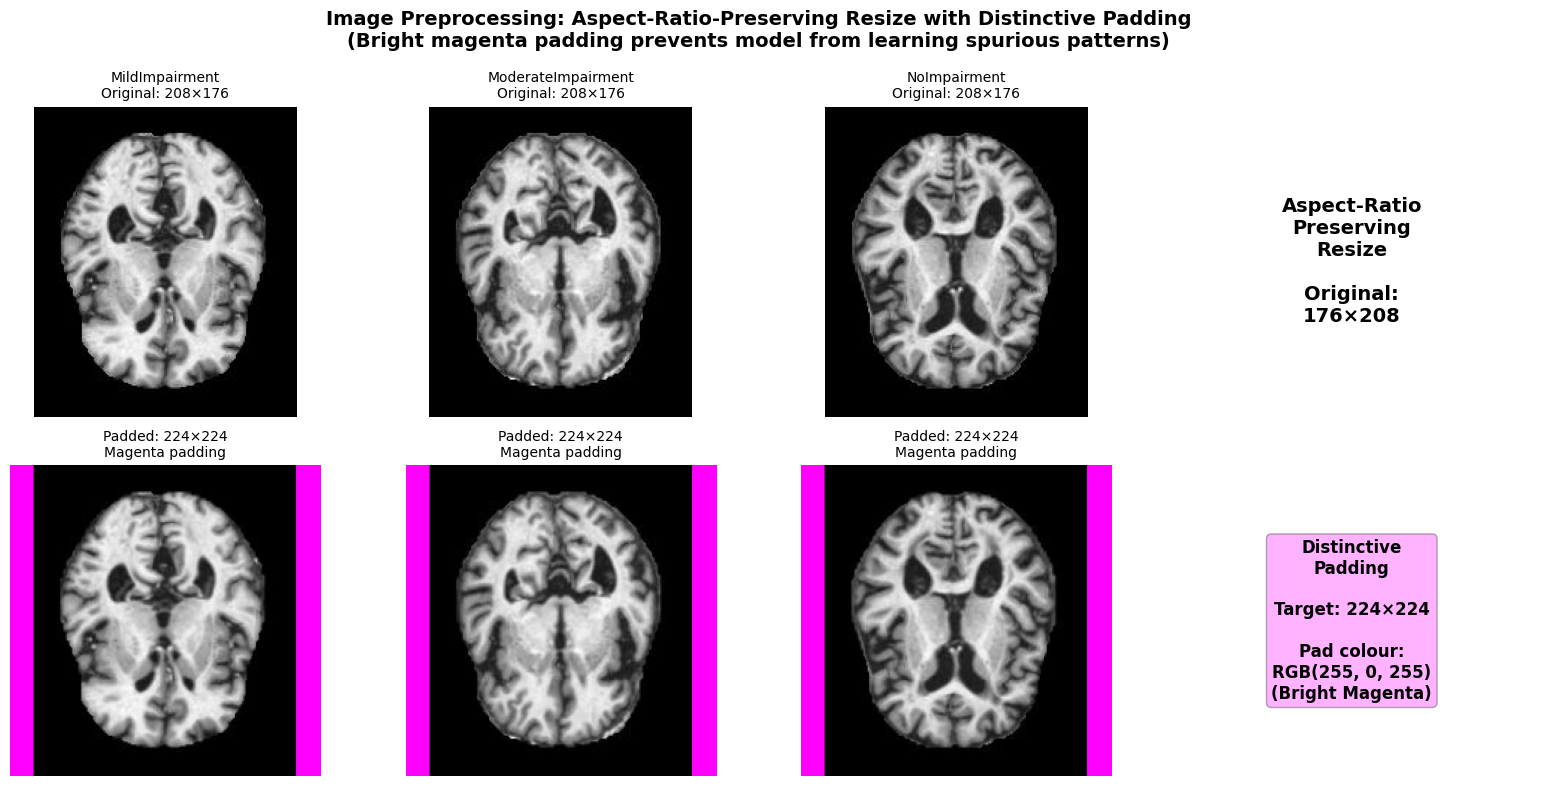

Saved: Output_20_02_2026__1052/Preprocessing_Demonstration_20_02_2026__1052.png


In [ ]:
def explore_dataset(data_dir):
    """
    Explore the dataset structure, class distribution, and image dimensions.
    """
    print("=" * 50)
    print("DATASET EXPLORATION")
    print("=" * 50)

    class_counts = {}
    total_images = 0
    sample_dims = None

    for class_name in sorted(os.listdir(data_dir)):
        class_path = data_dir / class_name
        if class_path.is_dir():
            images = list(class_path.glob('*.[jJ][pP][gG]')) + \
                     list(class_path.glob('*.[jJ][pP][eE][gG]')) + \
                     list(class_path.glob('*.[pP][nN][gG]'))
            num_images = len(images)
            class_counts[class_name] = num_images
            total_images += num_images

            if sample_dims is None and len(images) > 0:
                sample_img = Image.open(images[0])
                sample_dims = sample_img.size

    print(f"\nDataset Location: {data_dir}")
    print(f"Total images: {total_images}")
    print(f"Number of classes: {len(class_counts)}")
    if sample_dims:
        print(f"Original image dimensions: {sample_dims[1]} x {sample_dims[0]} (H x W)")

    print(f"\nClass distribution:")
    for class_name, count in sorted(class_counts.items()):
        percentage = (count / total_images) * 100
        bar = '█' * int(percentage / 2)
        print(f"  {class_name:20s}: {count:>5} images ({percentage:>5.1f}%) {bar}")

    counts = list(class_counts.values())
    imbalance_ratio = max(counts) / min(counts)
    print(f"\nClass imbalance ratio: {imbalance_ratio:.2f}:1")
    if imbalance_ratio > 2:
        print("⚠ Warning: Significant class imbalance detected.")
        print("  → Using stratified splitting to maintain proportions")
        print("  → Using weighted loss function")
        print("  → Using weighted random sampling")

    return class_counts, total_images

# Check if data directory exists
if DATA_DIR.exists():
    class_counts, total_images = explore_dataset(DATA_DIR)
    # Demonstrate padding transform
    demonstrate_padding_transform(DATA_DIR, OUTPUT_DIR)
else:
    print(f"⚠ Data directory not found: {DATA_DIR}")
    print("Please update DATA_DIR in the Configuration section.")
    class_counts, total_images = {}, 0

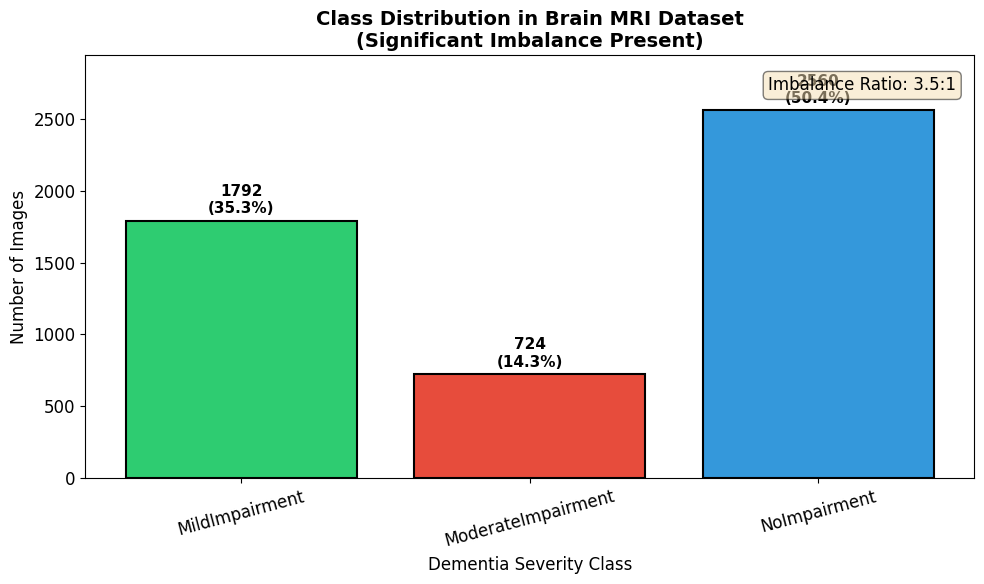

Saved: Output_20_02_2026__1052/Class_Distribution_20_02_2026__1052.png


In [ ]:
def visualise_class_distribution(class_counts, output_dir):
    """Visualise class distribution as a bar chart."""
    if not class_counts:
        print("No class data to visualise.")
        return

    fig, ax = plt.subplots(figsize=(10, 6))

    classes = list(class_counts.keys())
    counts = list(class_counts.values())
    total = sum(counts)
    colours = ['#2ecc71', '#e74c3c', '#3498db']

    bars = ax.bar(classes, counts, color=colours, edgecolor='black', linewidth=1.5)

    for bar, count in zip(bars, counts):
        percentage = count / total * 100
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                f'{count}\n({percentage:.1f}%)', ha='center', va='bottom',
                fontweight='bold', fontsize=11)

    ax.set_xlabel('Dementia Severity Class', fontsize=12)
    ax.set_ylabel('Number of Images', fontsize=12)
    ax.set_title('Class Distribution in Brain MRI Dataset\n(Significant Imbalance Present)',
                 fontweight='bold', fontsize=14)
    ax.set_ylim(0, max(counts) * 1.15)

    imbalance_ratio = max(counts) / min(counts)
    ax.text(0.98, 0.95, f'Imbalance Ratio: {imbalance_ratio:.1f}:1',
            transform=ax.transAxes, ha='right', va='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.xticks(rotation=15)
    plt.tight_layout()

    save_path = output_dir / f'Class_Distribution_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

if class_counts:
    visualise_class_distribution(class_counts, OUTPUT_DIR)

<hr style="border:1px solid black"> </hr>

## 8. Data Preparation with Stratified Splitting

**Important:** If you re-run the data splitting cells, the old split folders will be automatically replaced with new ones to avoid duplicate training datasets.

In [ ]:
# Define transforms using aspect-ratio-preserving resize with distinctive padding

# Basic transforms (NO augmentation) - for baseline model
basic_transforms = transforms.Compose([
    ResizeWithPad(IMAGE_SIZE, fill=PADDING_COLOUR),  # Aspect-ratio-preserving resize with magenta padding
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# ============================================================================
# CLINICALLY-MEANINGFUL AUGMENTATION TRANSFORMS FOR BRAIN MRI
# ============================================================================
# Standard computer vision augmentations (rotation, vertical flip) are
# INAPPROPRIATE for medical imaging because:
#   - MRI scans are ALWAYS acquired in standardised orientation
#   - Vertical flip would show brain upside-down (never happens clinically)
#   - Rotation would show tilted brain (radiologists never see this)
#
# Instead, we use augmentations that simulate REALISTIC clinical variations:
#   - Brightness/contrast: Different scanner calibrations
#   - Small translation: Patient positioning variation
#   - Small scaling: Field-of-view / slice thickness differences
#   - Gaussian blur: Slight motion artifacts or acquisition noise
# ============================================================================

augmentation_transforms = transforms.Compose([
    ResizeWithPad(IMAGE_SIZE, fill=PADDING_COLOUR),  # Aspect-ratio-preserving resize

    # Small affine transformation - simulates realistic clinical variations
    # NO rotation (scans are always standardised orientation)
    transforms.RandomAffine(
        degrees=0,                # NO rotation - MRI orientation is standardised
        translate=(0.05, 0.05),   # Up to 5% shift - patient positioning variation
        scale=(0.95, 1.05),       # ±5% zoom - field-of-view differences
        fill=PADDING_COLOUR       # Use padding colour for any new pixels
    ),

    # Brightness/contrast variation - simulates different scanner calibrations
    transforms.ColorJitter(brightness=0.15, contrast=0.15),

    # Gaussian blur - simulates slight motion or acquisition artifacts
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.5))
    ], p=0.2),

    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation/Test transforms (no augmentation)
val_transforms = transforms.Compose([
    ResizeWithPad(IMAGE_SIZE, fill=PADDING_COLOUR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("Transforms defined with aspect-ratio-preserving resize:")
print(f"  Input: {ORIGINAL_HEIGHT}x{ORIGINAL_WIDTH} → Output: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Padding colour: RGB{PADDING_COLOUR} (bright magenta)")
print("\n  basic_transforms (Exp 1):")
print("    - Resize with padding → Normalise")
print("\n  augmentation_transforms (Exp 2-4) - CLINICALLY APPROPRIATE:")
print("    - Resize with padding")
print("    - Random translation (±5%) - patient positioning")
print("    - Random scale (±5%) - field-of-view variation")
print("    - Brightness/contrast jitter - scanner calibration")
print("    - Random Gaussian blur (p=0.2) - motion artifacts")
print("    - Normalise")
print("\n  val_transforms:")
print("    - Resize with padding → Normalise (no augmentation)")

Transforms defined with aspect-ratio-preserving resize:
  Input: 176x208 → Output: 224x224
  Padding colour: RGB(255, 0, 255) (bright magenta)

  basic_transforms (Exp 1):
    - Resize with padding → Normalise

  augmentation_transforms (Exp 2-4) - CLINICALLY APPROPRIATE:
    - Resize with padding
    - Random translation (±5%) - patient positioning
    - Random scale (±5%) - field-of-view variation
    - Brightness/contrast jitter - scanner calibration
    - Random Gaussian blur (p=0.2) - motion artifacts
    - Normalise

  val_transforms:
    - Resize with padding → Normalise (no augmentation)


In [ ]:
class TransformSubset(Dataset):
    """
    Wrapper to apply transforms to a subset of data.
    Allows different transforms for train/val/test splits.
    """
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
# Global variable to store test indices for single image testing
GLOBAL_TEST_INDICES = None
GLOBAL_FULL_DATASET = None

def create_stratified_data_loaders(data_dir, train_transforms, val_transforms, batch_size,
                                    test_split=0.15, val_split=0.15, use_weighted_sampling=True,
                                    save_splits=True, output_dir=None):
    """
    Create train, validation, and test data loaders with STRATIFIED splitting.

    If save_splits is True, the split indices will be saved to disk.
    If the splits directory already exists, it will be REPLACED with new splits.
    """
    global GLOBAL_TEST_INDICES, GLOBAL_FULL_DATASET

    print("\n" + "="*50)
    print("CREATING STRATIFIED DATA SPLITS")
    print("="*50)

    # Handle existing splits directory - REPLACE if exists
    if output_dir is not None and save_splits:
        splits_dir = Path(output_dir) / 'data_splits'
        if splits_dir.exists():
            print(f"\n⚠ Existing splits directory found at {splits_dir}")
            print("  → Removing old splits to avoid duplicates...")
            shutil.rmtree(splits_dir)
            print("  → Old splits removed successfully.")
        splits_dir.mkdir(parents=True, exist_ok=True)

    full_dataset = datasets.ImageFolder(root=data_dir)
    GLOBAL_FULL_DATASET = full_dataset  # Store for single image testing
    class_names = full_dataset.classes
    targets = np.array(full_dataset.targets)
    indices = np.arange(len(full_dataset))

    print(f"\nTotal samples: {len(full_dataset)}")
    print(f"Classes: {class_names}")

    # First split: separate test set (stratified)
    train_val_indices, test_indices = train_test_split(
        indices,
        test_size=test_split,
        stratify=targets,
        random_state=42
    )

    # Second split: separate validation from training (stratified)
    train_val_targets = targets[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=val_split / (1 - test_split),
        stratify=train_val_targets,
        random_state=42
    )

    # Store test indices globally for single image testing
    GLOBAL_TEST_INDICES = test_indices

    print(f"\nStratified split sizes:")
    print(f"  Training:   {len(train_indices)} samples ({len(train_indices)/len(full_dataset)*100:.1f}%)")
    print(f"  Validation: {len(val_indices)} samples ({len(val_indices)/len(full_dataset)*100:.1f}%)")
    print(f"  Test:       {len(test_indices)} samples ({len(test_indices)/len(full_dataset)*100:.1f}%)")

    # Save splits if requested
    if output_dir is not None and save_splits:
        np.save(splits_dir / 'train_indices.npy', train_indices)
        np.save(splits_dir / 'val_indices.npy', val_indices)
        np.save(splits_dir / 'test_indices.npy', test_indices)
        print(f"\n✓ Split indices saved to: {splits_dir}")

        # Also save the file paths for the test set (useful for single image testing)
        test_files = [full_dataset.samples[i][0] for i in test_indices]
        with open(splits_dir / 'test_files.txt', 'w') as f:
            for file_path in test_files:
                f.write(f"{file_path}\n")
        print(f"✓ Test file paths saved to: {splits_dir / 'test_files.txt'}")

    # Verify stratification
    print(f"\nClass distribution verification:")
    for split_name, split_indices in [('Train', train_indices), ('Val', val_indices), ('Test', test_indices)]:
        split_targets = targets[split_indices]
        counts = Counter(split_targets)
        total = len(split_indices)
        props = [f"{class_names[i]}: {counts[i]/total*100:.1f}%" for i in range(len(class_names))]
        print(f"  {split_name}: {', '.join(props)}")

    # Create subsets
    train_subset = Subset(full_dataset, train_indices)
    val_subset = Subset(full_dataset, val_indices)
    test_subset = Subset(full_dataset, test_indices)

    # Calculate class weights
    train_targets = targets[train_indices]
    class_counts = Counter(train_targets)
    total_train = len(train_targets)

    class_weights = torch.tensor([total_train / (len(class_names) * class_counts[i])
                                   for i in range(len(class_names))], dtype=torch.float32)

    print(f"\nClass weights for loss function (inverse frequency):")
    for i, name in enumerate(class_names):
        print(f"  {name}: {class_weights[i]:.4f}")

    # Apply transforms
    train_dataset = TransformSubset(train_subset, train_transforms)
    val_dataset = TransformSubset(val_subset, val_transforms)
    test_dataset = TransformSubset(test_subset, val_transforms)

    # Create weighted sampler
    if use_weighted_sampling:
        sample_weights = [class_weights[targets[i]].item() for i in train_indices]
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        train_loader = DataLoader(train_dataset, batch_size=batch_size,
                                  sampler=sampler, num_workers=2, pin_memory=True)
        print("\n✓ Using weighted random sampling for training (addresses class imbalance)")
    else:
        train_loader = DataLoader(train_dataset, batch_size=batch_size,
                                  shuffle=True, num_workers=2, pin_memory=True)

    val_loader = DataLoader(val_dataset, batch_size=batch_size,
                            shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size,
                             shuffle=False, num_workers=2, pin_memory=True)

    return train_loader, val_loader, test_loader, class_names, class_weights

In [ ]:
def get_random_test_image_path():
    """
    Get a random image path from the test set for single image testing.
    """
    global GLOBAL_TEST_INDICES, GLOBAL_FULL_DATASET

    if GLOBAL_TEST_INDICES is None or GLOBAL_FULL_DATASET is None:
        print("❌ Error: Data splits have not been created yet.")
        print("Please run the data loading cells first.")
        return None

    random_idx = random.choice(GLOBAL_TEST_INDICES)
    file_path = GLOBAL_FULL_DATASET.samples[random_idx][0]
    return file_path

def list_test_images(n=10):
    """
    List n random image paths from the test set.
    """
    global GLOBAL_TEST_INDICES, GLOBAL_FULL_DATASET

    if GLOBAL_TEST_INDICES is None or GLOBAL_FULL_DATASET is None:
        print("❌ Error: Data splits have not been created yet.")
        return []

    sample_indices = random.sample(list(GLOBAL_TEST_INDICES), min(n, len(GLOBAL_TEST_INDICES)))
    paths = [GLOBAL_FULL_DATASET.samples[i][0] for i in sample_indices]

    print(f"\nSample of {len(paths)} test images:")
    print("="*60)
    for i, path in enumerate(paths, 1):
        class_name = Path(path).parent.name
        filename = Path(path).name
        print(f"{i:2d}. [{class_name}] {filename}")
    print("="*60)
    print("\nCopy any filename above to test with predict_single_image()")

    return paths

print("Helper functions defined:")
print("  - get_random_test_image_path(): Returns a random test image path")
print("  - list_test_images(n): Lists n random test image paths")

Helper functions defined:
  - get_random_test_image_path(): Returns a random test image path
  - list_test_images(n): Lists n random test image paths


<hr style="border:1px solid black"> </hr>

## 9. Model Definitions

In [ ]:
class BaselineCNN(nn.Module):
    """
    Simple CNN from scratch - baseline model.

    Architecture Design Choices:
    - Uses Global Average Pooling (GAP) instead of large fully-connected layers
    - This reduces parameters from ~51M to ~300K, preventing memorisation
    - GAP forces the network to learn spatially-invariant features
    - Batch normalisation for training stability
    - Dropout for regularisation

    The small parameter count ensures the model must learn generalisable
    features rather than memorising the training set.
    """
    def __init__(self, num_classes, input_size=224):
        super(BaselineCNN, self).__init__()

        # Feature extraction with batch normalisation for stability
        self.features = nn.Sequential(
            # Block 1: 224 -> 112
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.25),

            # Block 2: 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.25),

            # Block 3: 56 -> 28
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.25),

            # Block 4: 28 -> 14
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.25),
        )

        # Global Average Pooling - reduces 256x14x14 to 256x1x1
        # This is KEY: prevents memorisation by removing spatial information
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Small classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

        self._count_parameters()

    def _count_parameters(self):
        total_params = sum(p.numel() for p in self.parameters())
        trainable_params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f"\nBaseline CNN Parameters:")
        print(f"  Total:     {total_params:,}")
        print(f"  Trainable: {trainable_params:,}")
        print(f"  Architecture: 4 conv blocks + Global Average Pooling + small MLP")

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

print("BaselineCNN class defined")
print("  - Uses Global Average Pooling (prevents memorisation)")
print("  - ~300K parameters (vs 51M in naive implementation)")

BaselineCNN class defined
  - Uses Global Average Pooling (prevents memorisation)
  - ~300K parameters (vs 51M in naive implementation)


In [ ]:
class ResNet50Classifier(nn.Module):
    """
    ResNet50 with transfer learning and configurable fine-tuning.

    Fine-tuning modes:
    - 'none': Freeze all backbone weights (only train classifier head)
    - 'partial': Unfreeze layer3 and layer4 (recommended for domain adaptation)
    - 'full': Unfreeze entire backbone (risk of catastrophic forgetting)

    For medical imaging, 'partial' is recommended because:
    - Early layers (layer1, layer2) learn generic features (edges, textures)
    - Later layers (layer3, layer4) learn domain-specific features
    - Unfreezing later layers allows adaptation to MRI characteristics
    """
    def __init__(self, num_classes, fine_tune_mode='partial'):
        super(ResNet50Classifier, self).__init__()

        print("Loading ResNet50 backbone (ImageNet pretrained)...")
        self.backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

        # Apply freezing strategy based on mode
        if fine_tune_mode == 'none':
            print("Freezing ALL backbone weights (classifier head only)")
            for param in self.backbone.parameters():
                param.requires_grad = False
        elif fine_tune_mode == 'partial':
            print("Partial fine-tuning: freezing layer1, layer2; unfreezing layer3, layer4")
            # Freeze early layers
            for name, param in self.backbone.named_parameters():
                if 'layer1' in name or 'layer2' in name or 'conv1' in name or 'bn1' in name:
                    param.requires_grad = False
                else:
                    param.requires_grad = True
        else:  # 'full'
            print("Full fine-tuning: all backbone weights trainable")
            for param in self.backbone.parameters():
                param.requires_grad = True

        # Replace classifier head
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(num_features, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        self._count_parameters()

    def _count_parameters(self):
        total_params = sum(p.numel() for p in self.parameters())
        trainable_params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen_params = total_params - trainable_params
        print(f"\nResNet50 Parameters:")
        print(f"  Total:     {total_params:,}")
        print(f"  Trainable: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
        print(f"  Frozen:    {frozen_params:,} ({frozen_params/total_params*100:.1f}%)")

    def forward(self, x):
        return self.backbone(x)

print("ResNet50Classifier class defined")
print("  - Supports: fine_tune_mode='none', 'partial', or 'full'")
print("  - Default: 'partial' (recommended for medical imaging)")

ResNet50Classifier class defined
  - Supports: fine_tune_mode='none', 'partial', or 'full'
  - Default: 'partial' (recommended for medical imaging)


In [ ]:
class ViTClassifier(nn.Module):
    """
    Vision Transformer (ViT-B/16) classifier using torchvision.

    Fine-tuning modes:
    - 'none': Freeze all backbone weights (only train classifier head)
    - 'partial': Unfreeze last N transformer layers (recommended)
    - 'full': Unfreeze entire backbone

    For medical imaging, 'partial' with 2-4 unfrozen layers is recommended
    because later transformer layers capture more task-specific representations.
    """
    def __init__(self, num_classes, fine_tune_mode='partial', num_unfrozen_layers=4, dropout_rate=0.3):
        super(ViTClassifier, self).__init__()

        print("Loading ViT-B/16 backbone (ImageNet-1K pretrained)...")
        print("  - Architecture: Vision Transformer Base with 16x16 patches")
        print("  - Parameters: ~86M total (768-dim embeddings, 12 layers, 12 heads)")

        weights = ViT_B_16_Weights.IMAGENET1K_V1
        self.backbone = vit_b_16(weights=weights)

        self.embedding_dim = self.backbone.heads.head.in_features
        print(f"  - Embedding dimension: {self.embedding_dim}")

        # Apply freezing strategy based on mode
        if fine_tune_mode == 'none':
            print("Freezing ALL backbone weights (classifier head only)")
            for param in self.backbone.parameters():
                param.requires_grad = False
        elif fine_tune_mode == 'partial':
            print(f"Partial fine-tuning: unfreezing last {num_unfrozen_layers} transformer layers")
            # First freeze everything
            for param in self.backbone.parameters():
                param.requires_grad = False
            # Then unfreeze last N encoder layers
            encoder_layers = list(self.backbone.encoder.layers)
            for layer in encoder_layers[-num_unfrozen_layers:]:
                for param in layer.parameters():
                    param.requires_grad = True
            # Also unfreeze the encoder layer norm
            for param in self.backbone.encoder.ln.parameters():
                param.requires_grad = True
        else:  # 'full'
            print("Full fine-tuning: all backbone weights trainable")
            for param in self.backbone.parameters():
                param.requires_grad = True

        # Replace classifier head
        self.backbone.heads.head = nn.Sequential(
            nn.LayerNorm(self.embedding_dim),
            nn.Dropout(p=dropout_rate),
            nn.Linear(self.embedding_dim, 256),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, num_classes)
        )

        # Always ensure classifier head is trainable
        for param in self.backbone.heads.parameters():
            param.requires_grad = True

        self._count_parameters()

    def _count_parameters(self):
        total_params = sum(p.numel() for p in self.parameters())
        trainable_params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen_params = total_params - trainable_params
        print(f"\nViT-B/16 Parameters:")
        print(f"  Total:     {total_params:,}")
        print(f"  Trainable: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
        print(f"  Frozen:    {frozen_params:,} ({frozen_params/total_params*100:.1f}%)")

    def forward(self, x):
        return self.backbone(x)

print("ViTClassifier class defined")
print("  - Supports: fine_tune_mode='none', 'partial', or 'full'")
print("  - Default: 'partial' with last 4 transformer layers unfrozen")

ViTClassifier class defined
  - Supports: fine_tune_mode='none', 'partial', or 'full'
  - Default: 'partial' with last 4 transformer layers unfrozen


<hr style="border:1px solid black"> </hr>

## 10. Training Functions

In [ ]:
class EarlyStopping:
    """Early stopping to prevent overfitting."""
    def __init__(self, patience=5, min_delta=0, restore_best_weights=True):
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.best_loss = None
        self.counter = 0
        self.best_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                return True
        else:
            self.best_loss = val_loss
            self.best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
        return False

    def restore(self, model):
        if self.restore_best_weights and self.best_weights is not None:
            model.load_state_dict(self.best_weights)

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    """Train the model for one epoch."""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc='Training', leave=False):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate(model, val_loader, criterion, device):
    """Validate the model."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs, device, patience=5, exp_name='model', exp_dir=None):
    """
    Full training loop with early stopping and automatic visualisation saving.
    """
    print(f"\n{'='*60}")
    print(f"TRAINING: {exp_name}")
    print(f"{'='*60}")

    early_stopping = EarlyStopping(patience=patience, restore_best_weights=True)

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1:02d}/{num_epochs}: "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        if early_stopping(val_loss, model):
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            early_stopping.restore(model)
            break

    print(f"\nTraining completed. Best validation loss: {early_stopping.best_loss:.4f}")

    # Save training history plot
    if exp_dir:
        save_training_history(history, exp_name, exp_dir)

    return history

<hr style="border:1px solid black"> </hr>

## 11. Experiment 1: Baseline CNN (No Augmentation)

This establishes our baseline performance using a simple CNN trained from scratch **without** any data augmentation.

In [ ]:
print("="*60)
print("EXPERIMENT 1: BASELINE CNN (NO AUGMENTATION)")
print("="*60)

EXP1_NAME = "Exp1_Baseline_CNN_NoAug"
EXP1_DIR = OUTPUT_DIR / 'exp1'

# Create data loaders with NO augmentation
train_loader_exp1, val_loader_exp1, test_loader_exp1, class_names, class_weights = create_stratified_data_loaders(
    DATA_DIR,
    train_transforms=basic_transforms,
    val_transforms=val_transforms,
    batch_size=BATCH_SIZE,
    test_split=TEST_SPLIT,
    val_split=VAL_SPLIT,
    save_splits=True,
    output_dir=OUTPUT_DIR
)

EXPERIMENT 1: BASELINE CNN (NO AUGMENTATION)

CREATING STRATIFIED DATA SPLITS

Total samples: 5076
Classes: ['MildImpairment', 'ModerateImpairment', 'NoImpairment']

Stratified split sizes:
  Training:   3552 samples (70.0%)
  Validation: 762 samples (15.0%)
  Test:       762 samples (15.0%)

✓ Split indices saved to: Output_20_02_2026__1052/data_splits
✓ Test file paths saved to: Output_20_02_2026__1052/data_splits/test_files.txt

Class distribution verification:
  Train: MildImpairment: 35.3%, ModerateImpairment: 14.2%, NoImpairment: 50.5%
  Val: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%
  Test: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%

Class weights for loss function (inverse frequency):
  MildImpairment: 0.9442
  ModerateImpairment: 2.3399
  NoImpairment: 0.6607

✓ Using weighted random sampling for training (addresses class imbalance)


In [ ]:
# Create baseline model
set_seed(42)
model_exp1 = BaselineCNN(num_classes=NUM_CLASSES, input_size=IMAGE_SIZE).to(device)

criterion_exp1 = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer_exp1 = optim.Adam(model_exp1.parameters(), lr=LEARNING_RATE)

print(f"\nLoss: CrossEntropyLoss (with class weights for imbalance)")
print(f"Optimizer: Adam (lr={LEARNING_RATE})")


Baseline CNN Parameters:
  Total:     1,207,459
  Trainable: 1,207,459
  Architecture: 4 conv blocks + Global Average Pooling + small MLP

Loss: CrossEntropyLoss (with class weights for imbalance)
Optimizer: Adam (lr=0.0001)



TRAINING: Exp1_Baseline_CNN_NoAug


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 01/30: Train Loss: 0.9845, Train Acc: 0.3392 | Val Loss: 1.1406, Val Acc: 0.1430


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 02/30: Train Loss: 0.9615, Train Acc: 0.3280 | Val Loss: 1.0966, Val Acc: 0.1430


Training:   0%|          | 0/111 [00:00<?, ?it/s]

... (17 outputs left out)

Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 12/30: Train Loss: 0.8264, Train Acc: 0.4927 | Val Loss: 0.9985, Val Acc: 0.4409


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 13/30: Train Loss: 0.8051, Train Acc: 0.5045 | Val Loss: 0.9587, Val Acc: 0.4580

Early stopping triggered at epoch 13

Training completed. Best validation loss: 0.9526


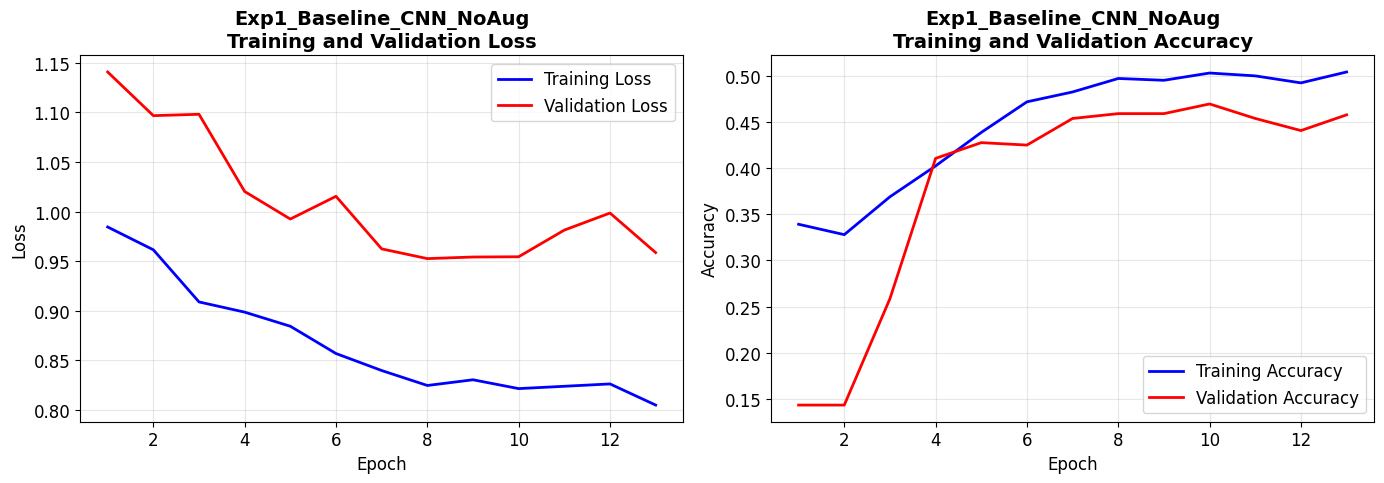

Saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_Training_History_20_02_2026__1052.png


In [ ]:
# Train baseline model
history_exp1 = train_model(
    model_exp1, train_loader_exp1, val_loader_exp1, criterion_exp1, optimizer_exp1,
    num_epochs=NUM_EPOCHS, device=device, patience=EARLY_STOP_PATIENCE,
    exp_name=EXP1_NAME, exp_dir=EXP1_DIR
)


EVALUATION: Exp1_Baseline_CNN_NoAug
CLASSIFICATION METRICS
Accuracy:  0.4698 (46.98%)
Precision: 0.5463 (54.63%)
Recall:    0.4698 (46.98%)
F1-Score:  0.4485 (44.85%)

Classification Report:
                    precision    recall  f1-score   support

    MildImpairment       0.39      0.08      0.13       269
ModerateImpairment       0.24      0.82      0.37       109
      NoImpairment       0.75      0.64      0.69       384

          accuracy                           0.47       762
         macro avg       0.46      0.51      0.40       762
      weighted avg       0.55      0.47      0.45       762


--- Generating Visualisations ---


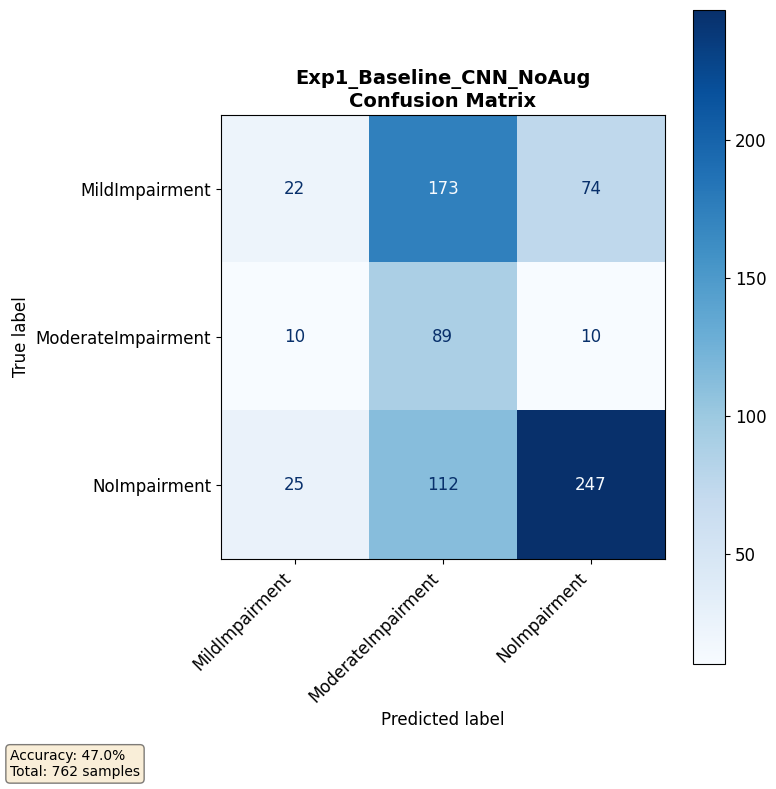

Saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_Confusion_Matrix_20_02_2026__1052.png


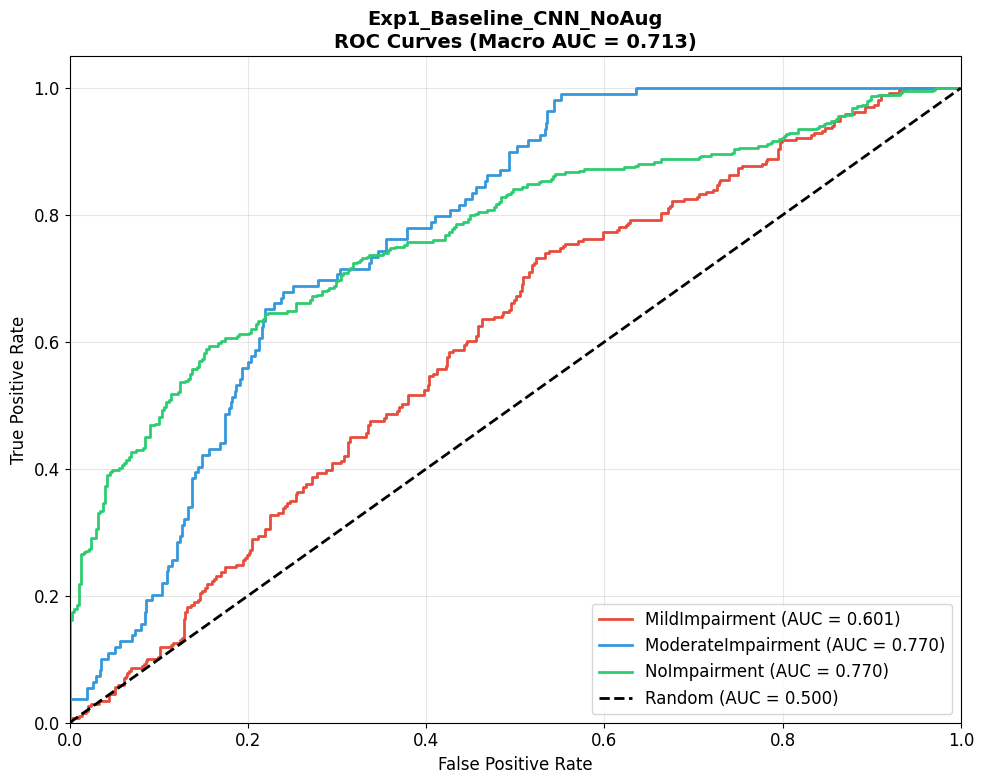

Saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_ROC_Curves_20_02_2026__1052.png


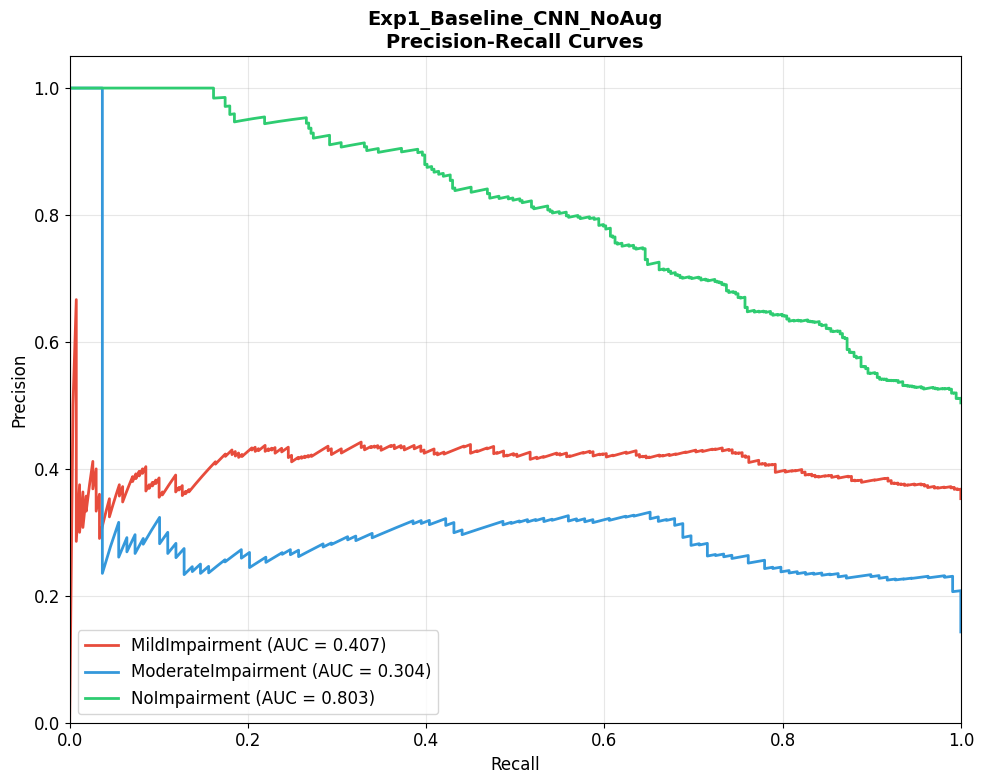

Saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_PR_Curves_20_02_2026__1052.png


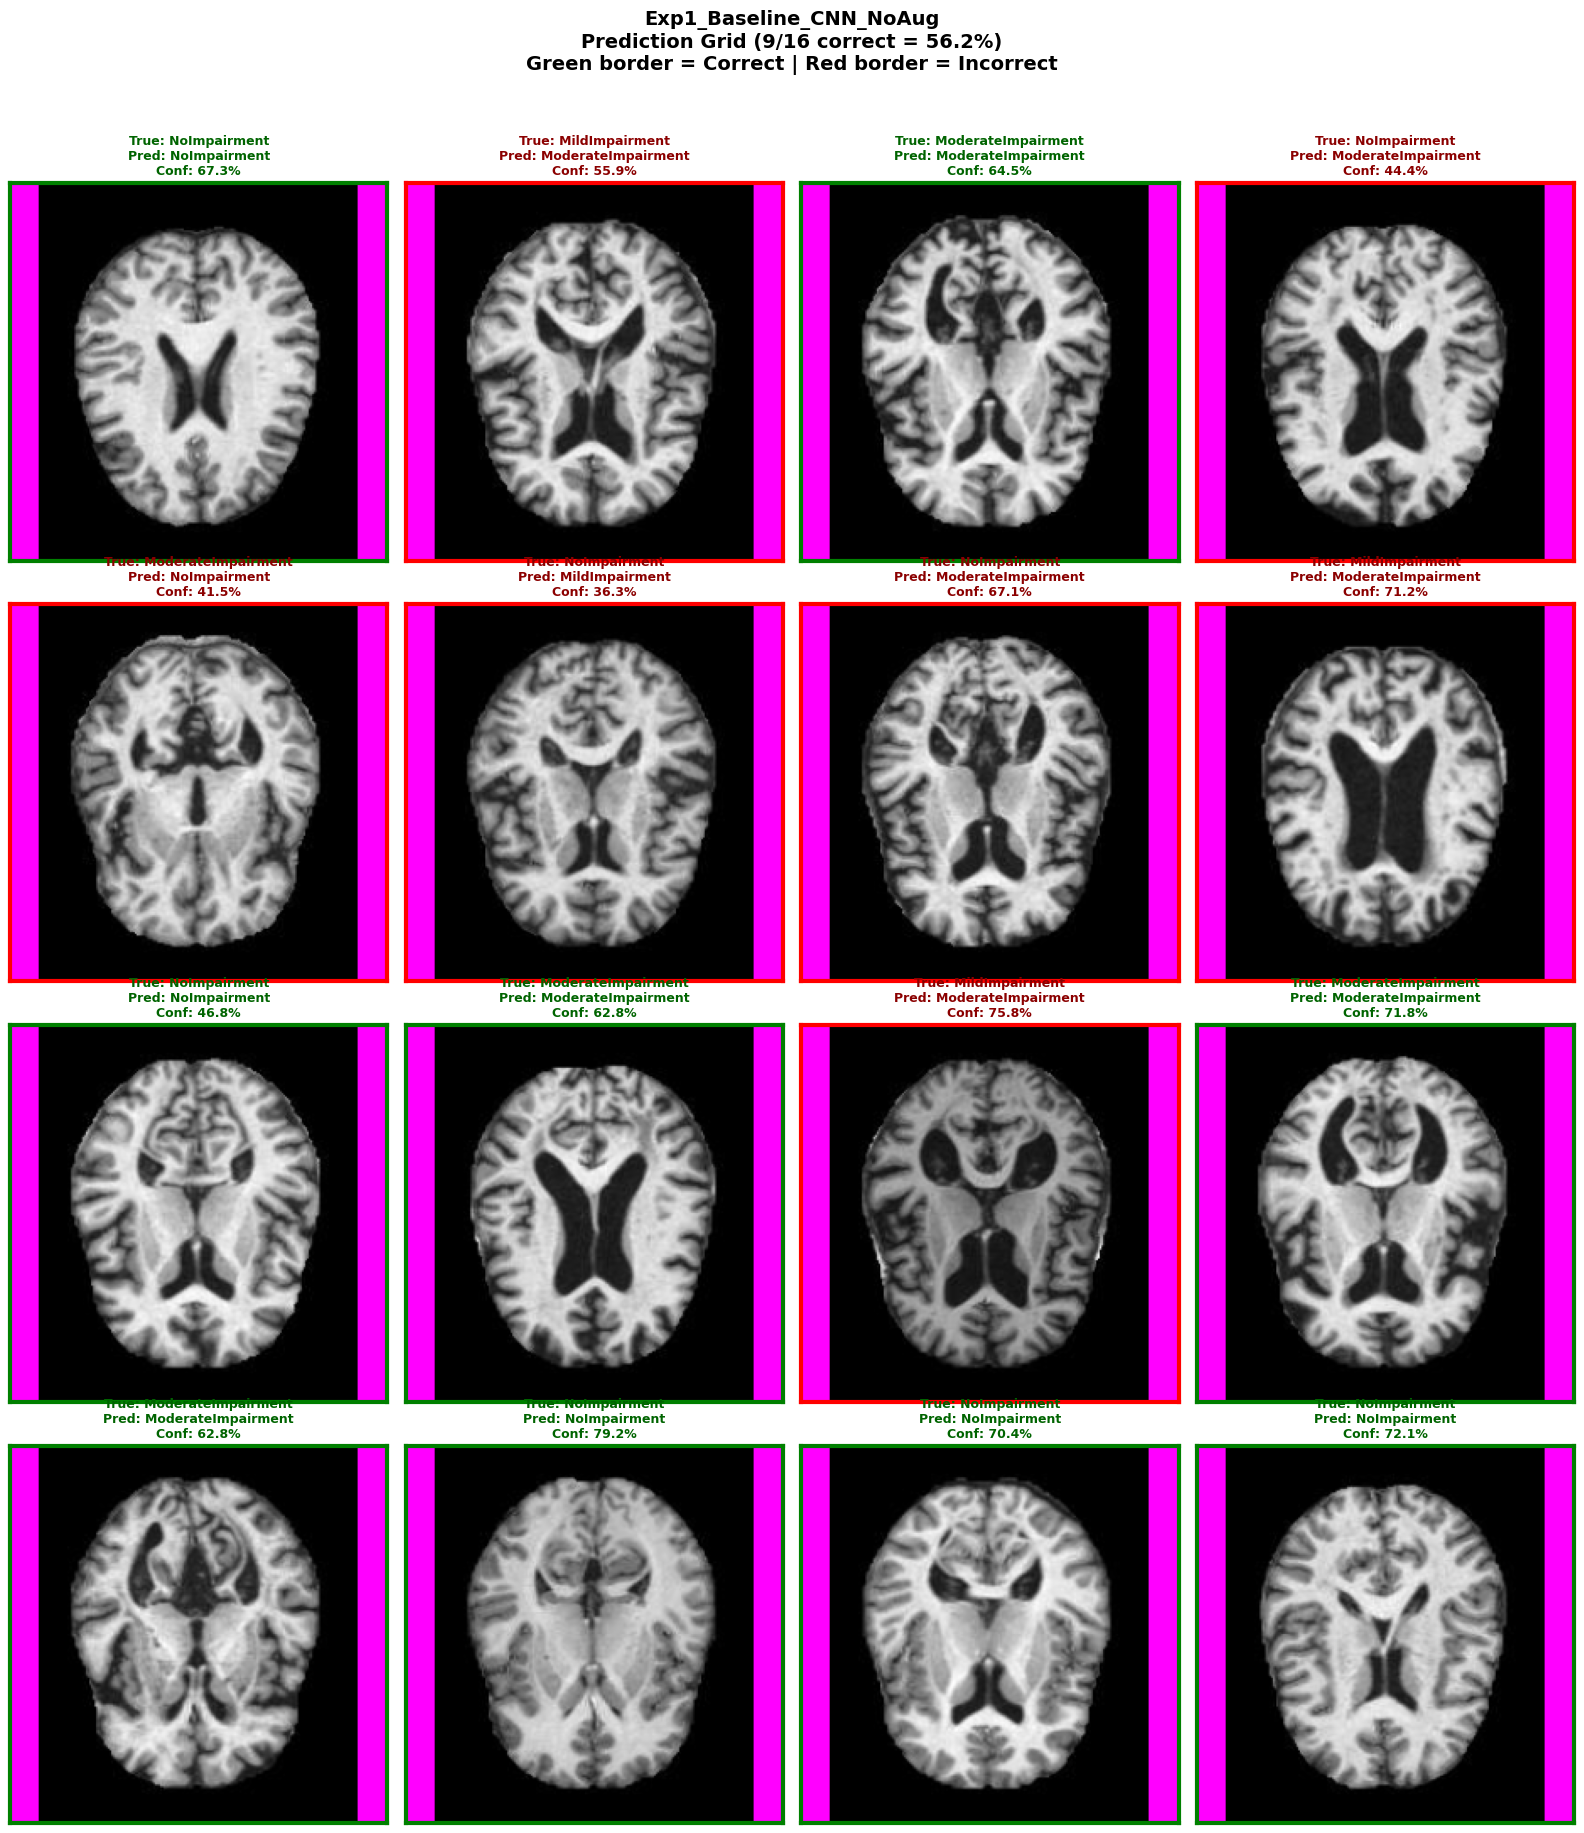

Saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_Prediction_Grid_20_02_2026__1052.png

✓ All visualisations saved to: Output_20_02_2026__1052/exp1

Model saved: Output_20_02_2026__1052/exp1/Exp1_Baseline_CNN_NoAug_Model_20_02_2026__1052.pth


In [ ]:
# Run full evaluation and generate all visualisations
metrics_exp1, auc_exp1, y_true_exp1, y_pred_exp1, y_prob_exp1 = run_full_evaluation(
    model_exp1, test_loader_exp1, class_names, EXP1_NAME, EXP1_DIR, device
)

# Save model
torch.save(model_exp1.state_dict(), EXP1_DIR / f'{EXP1_NAME}_Model_{TIMESTAMP}.pth')
print(f"\nModel saved: {EXP1_DIR / f'{EXP1_NAME}_Model_{TIMESTAMP}.pth'}")

### Test Single Image from Test Split (Experiment 1)

Test the model on individual images from the test split to verify generalisation. These images were **never seen during training**.

In [ ]:
# List some test images you can use
print("Available test images (never seen during training):")
test_image_paths = list_test_images(n=10)

Available test images (never seen during training):

Sample of 10 test images:
 1. [NoImpairment] NoImpairment_image2012.jpg
 2. [NoImpairment] NoImpairment_image223.jpg
 3. [ModerateImpairment] ModerateImpairment_image468.jpg
 4. [MildImpairment] MildImpairment_image646.jpg
 5. [MildImpairment] MildImpairment_image325.jpg
 6. [NoImpairment] NoImpairment_image1907.jpg
 7. [NoImpairment] NoImpairment_image66.jpg
 8. [MildImpairment] MildImpairment_image38.jpg
 9. [NoImpairment] NoImpairment_image2475.jpg
10. [NoImpairment] NoImpairment_image515.jpg

Copy any filename above to test with predict_single_image()


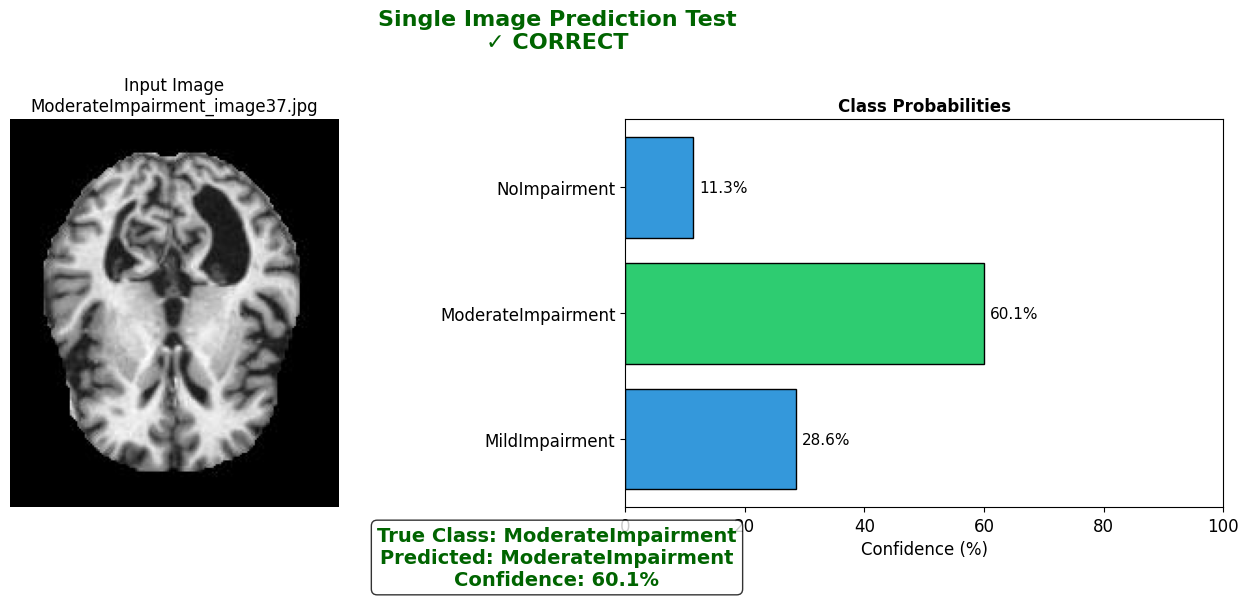


SINGLE IMAGE PREDICTION RESULT
Image: ModerateImpairment_image37.jpg
True Class: ModerateImpairment
Predicted Class: ModerateImpairment
Confidence: 60.05%
Status: ✓ CORRECT

Class Probabilities:
  MildImpairment: 28.61%
  ModerateImpairment: 60.05%
  NoImpairment: 11.34%


In [ ]:
# =============================================================
# TEST SINGLE IMAGE - EXPERIMENT 1
# =============================================================
# Enter the file path or filename of an image from the test split
# to verify that the model has truly generalised.
#
# Options:
#   1. Use a full path: 'C:/path/to/image.jpg'
#   2. Use just the filename: 'image_123.jpg' (will search in DATA_DIR)
#   3. Use get_random_test_image_path() for a random test image
# =============================================================

# Option 1: Enter your own path/filename
# TEST_IMAGE_PATH = "your_image_filename.jpg"  # Uncomment and modify

# Option 2: Use a random test image
TEST_IMAGE_PATH = get_random_test_image_path()

if TEST_IMAGE_PATH:
    result_exp1 = predict_single_image(
        model=model_exp1,
        image_path=TEST_IMAGE_PATH,
        class_names=class_names,
        device=device,
        data_dir=DATA_DIR
    )

<hr style="border:1px solid black"> </hr>

## 12. Experiment 2: Baseline CNN with Data Augmentation

Now we evaluate the impact of data augmentation on the same baseline architecture.

In [ ]:
print("="*60)
print("EXPERIMENT 2: BASELINE CNN WITH DATA AUGMENTATION")
print("="*60)

EXP2_NAME = "Exp2_Baseline_CNN_WithAug"
EXP2_DIR = OUTPUT_DIR / 'exp2'

# Create data loaders WITH clinically-appropriate augmentation
train_loader_exp2, val_loader_exp2, test_loader_exp2, _, _ = create_stratified_data_loaders(
    DATA_DIR,
    train_transforms=augmentation_transforms,
    val_transforms=val_transforms,
    batch_size=BATCH_SIZE,
    test_split=TEST_SPLIT,
    val_split=VAL_SPLIT,
    save_splits=False,
    output_dir=OUTPUT_DIR
)

print("\nClinically-appropriate augmentation techniques applied:")
print("  ✓ Random translation (±5%) - simulates patient positioning variation")
print("  ✓ Random scaling (±5%) - simulates field-of-view differences")
print("  ✓ Brightness/contrast jitter - simulates scanner calibration variation")
print("  ✓ Random Gaussian blur (p=0.2) - simulates motion/acquisition artifacts")
print("\nAugmentations NOT used (clinically unrealistic for brain MRI):")
print("  ✗ Rotation - MRI scans have standardised orientation")
print("  ✗ Vertical flip - brain would appear upside-down")

EXPERIMENT 2: BASELINE CNN WITH DATA AUGMENTATION

CREATING STRATIFIED DATA SPLITS

Total samples: 5076
Classes: ['MildImpairment', 'ModerateImpairment', 'NoImpairment']

Stratified split sizes:
  Training:   3552 samples (70.0%)
  Validation: 762 samples (15.0%)
  Test:       762 samples (15.0%)

Class distribution verification:
  Train: MildImpairment: 35.3%, ModerateImpairment: 14.2%, NoImpairment: 50.5%
  Val: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%
  Test: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%

Class weights for loss function (inverse frequency):
  MildImpairment: 0.9442
  ModerateImpairment: 2.3399
  NoImpairment: 0.6607

✓ Using weighted random sampling for training (addresses class imbalance)

Clinically-appropriate augmentation techniques applied:
  ✓ Random translation (±5%) - simulates patient positioning variation
  ✓ Random scaling (±5%) - simulates field-of-view differences
  ✓ Brightness/contrast jitter - simu

In [ ]:
# Create new baseline model (fresh weights)
set_seed(42)
model_exp2 = BaselineCNN(num_classes=NUM_CLASSES, input_size=IMAGE_SIZE).to(device)

criterion_exp2 = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer_exp2 = optim.Adam(model_exp2.parameters(), lr=LEARNING_RATE)


Baseline CNN Parameters:
  Total:     1,207,459
  Trainable: 1,207,459
  Architecture: 4 conv blocks + Global Average Pooling + small MLP



TRAINING: Exp2_Baseline_CNN_WithAug


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 01/30: Train Loss: 0.9867, Train Acc: 0.3409 | Val Loss: 1.1498, Val Acc: 0.1430


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 02/30: Train Loss: 0.9667, Train Acc: 0.3271 | Val Loss: 1.1128, Val Acc: 0.1430


Training:   0%|          | 0/111 [00:00<?, ?it/s]

... (23 outputs left out)

Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 15/30: Train Loss: 0.8030, Train Acc: 0.5039 | Val Loss: 1.0167, Val Acc: 0.4357


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 16/30: Train Loss: 0.8173, Train Acc: 0.4941 | Val Loss: 1.0205, Val Acc: 0.4094

Early stopping triggered at epoch 16

Training completed. Best validation loss: 0.9575


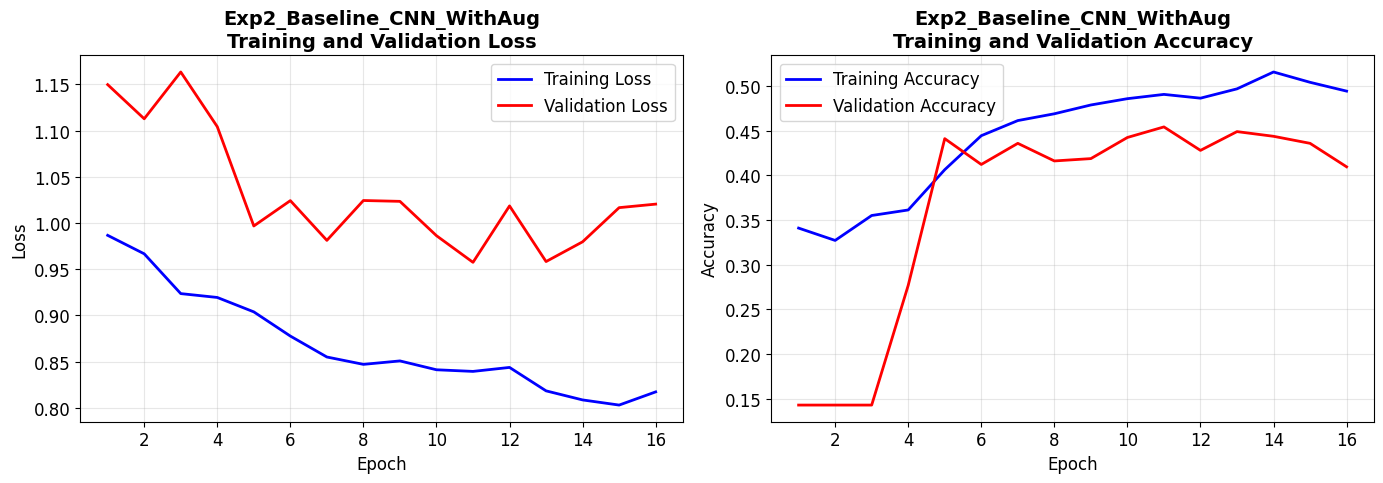

Saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_Training_History_20_02_2026__1052.png


In [ ]:
# Train with augmentation
history_exp2 = train_model(
    model_exp2, train_loader_exp2, val_loader_exp2, criterion_exp2, optimizer_exp2,
    num_epochs=NUM_EPOCHS, device=device, patience=EARLY_STOP_PATIENCE,
    exp_name=EXP2_NAME, exp_dir=EXP2_DIR
)


EVALUATION: Exp2_Baseline_CNN_WithAug
CLASSIFICATION METRICS
Accuracy:  0.4619 (46.19%)
Precision: 0.5279 (52.79%)
Recall:    0.4619 (46.19%)
F1-Score:  0.4371 (43.71%)

Classification Report:
                    precision    recall  f1-score   support

    MildImpairment       0.34      0.07      0.12       269
ModerateImpairment       0.24      0.85      0.38       109
      NoImpairment       0.74      0.62      0.68       384

          accuracy                           0.46       762
         macro avg       0.44      0.52      0.39       762
      weighted avg       0.53      0.46      0.44       762


--- Generating Visualisations ---


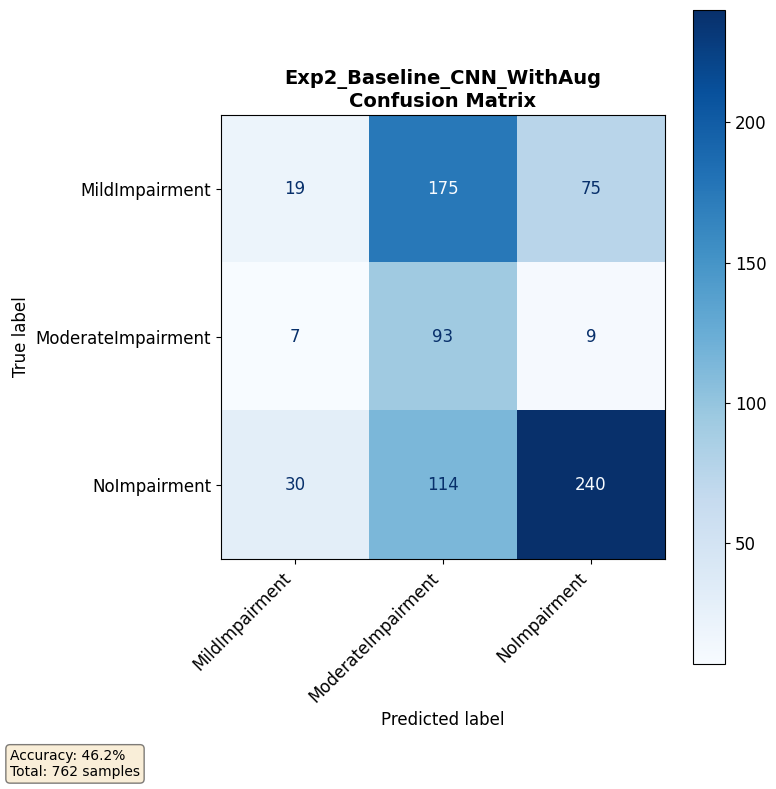

Saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_Confusion_Matrix_20_02_2026__1052.png


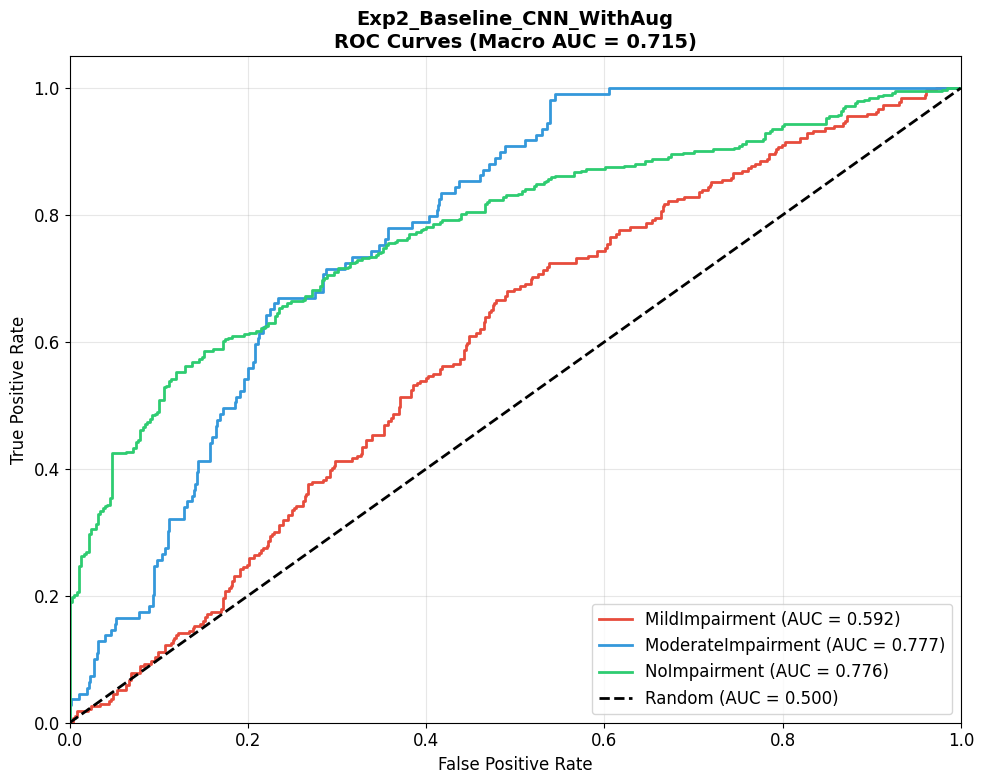

Saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_ROC_Curves_20_02_2026__1052.png


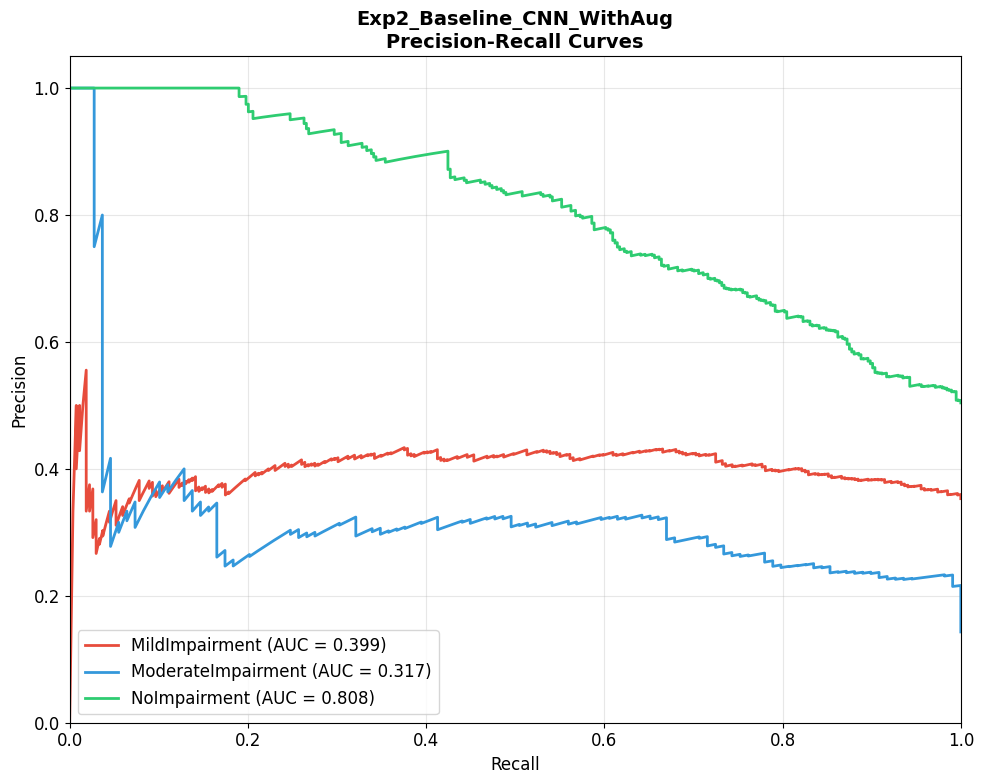

Saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_PR_Curves_20_02_2026__1052.png


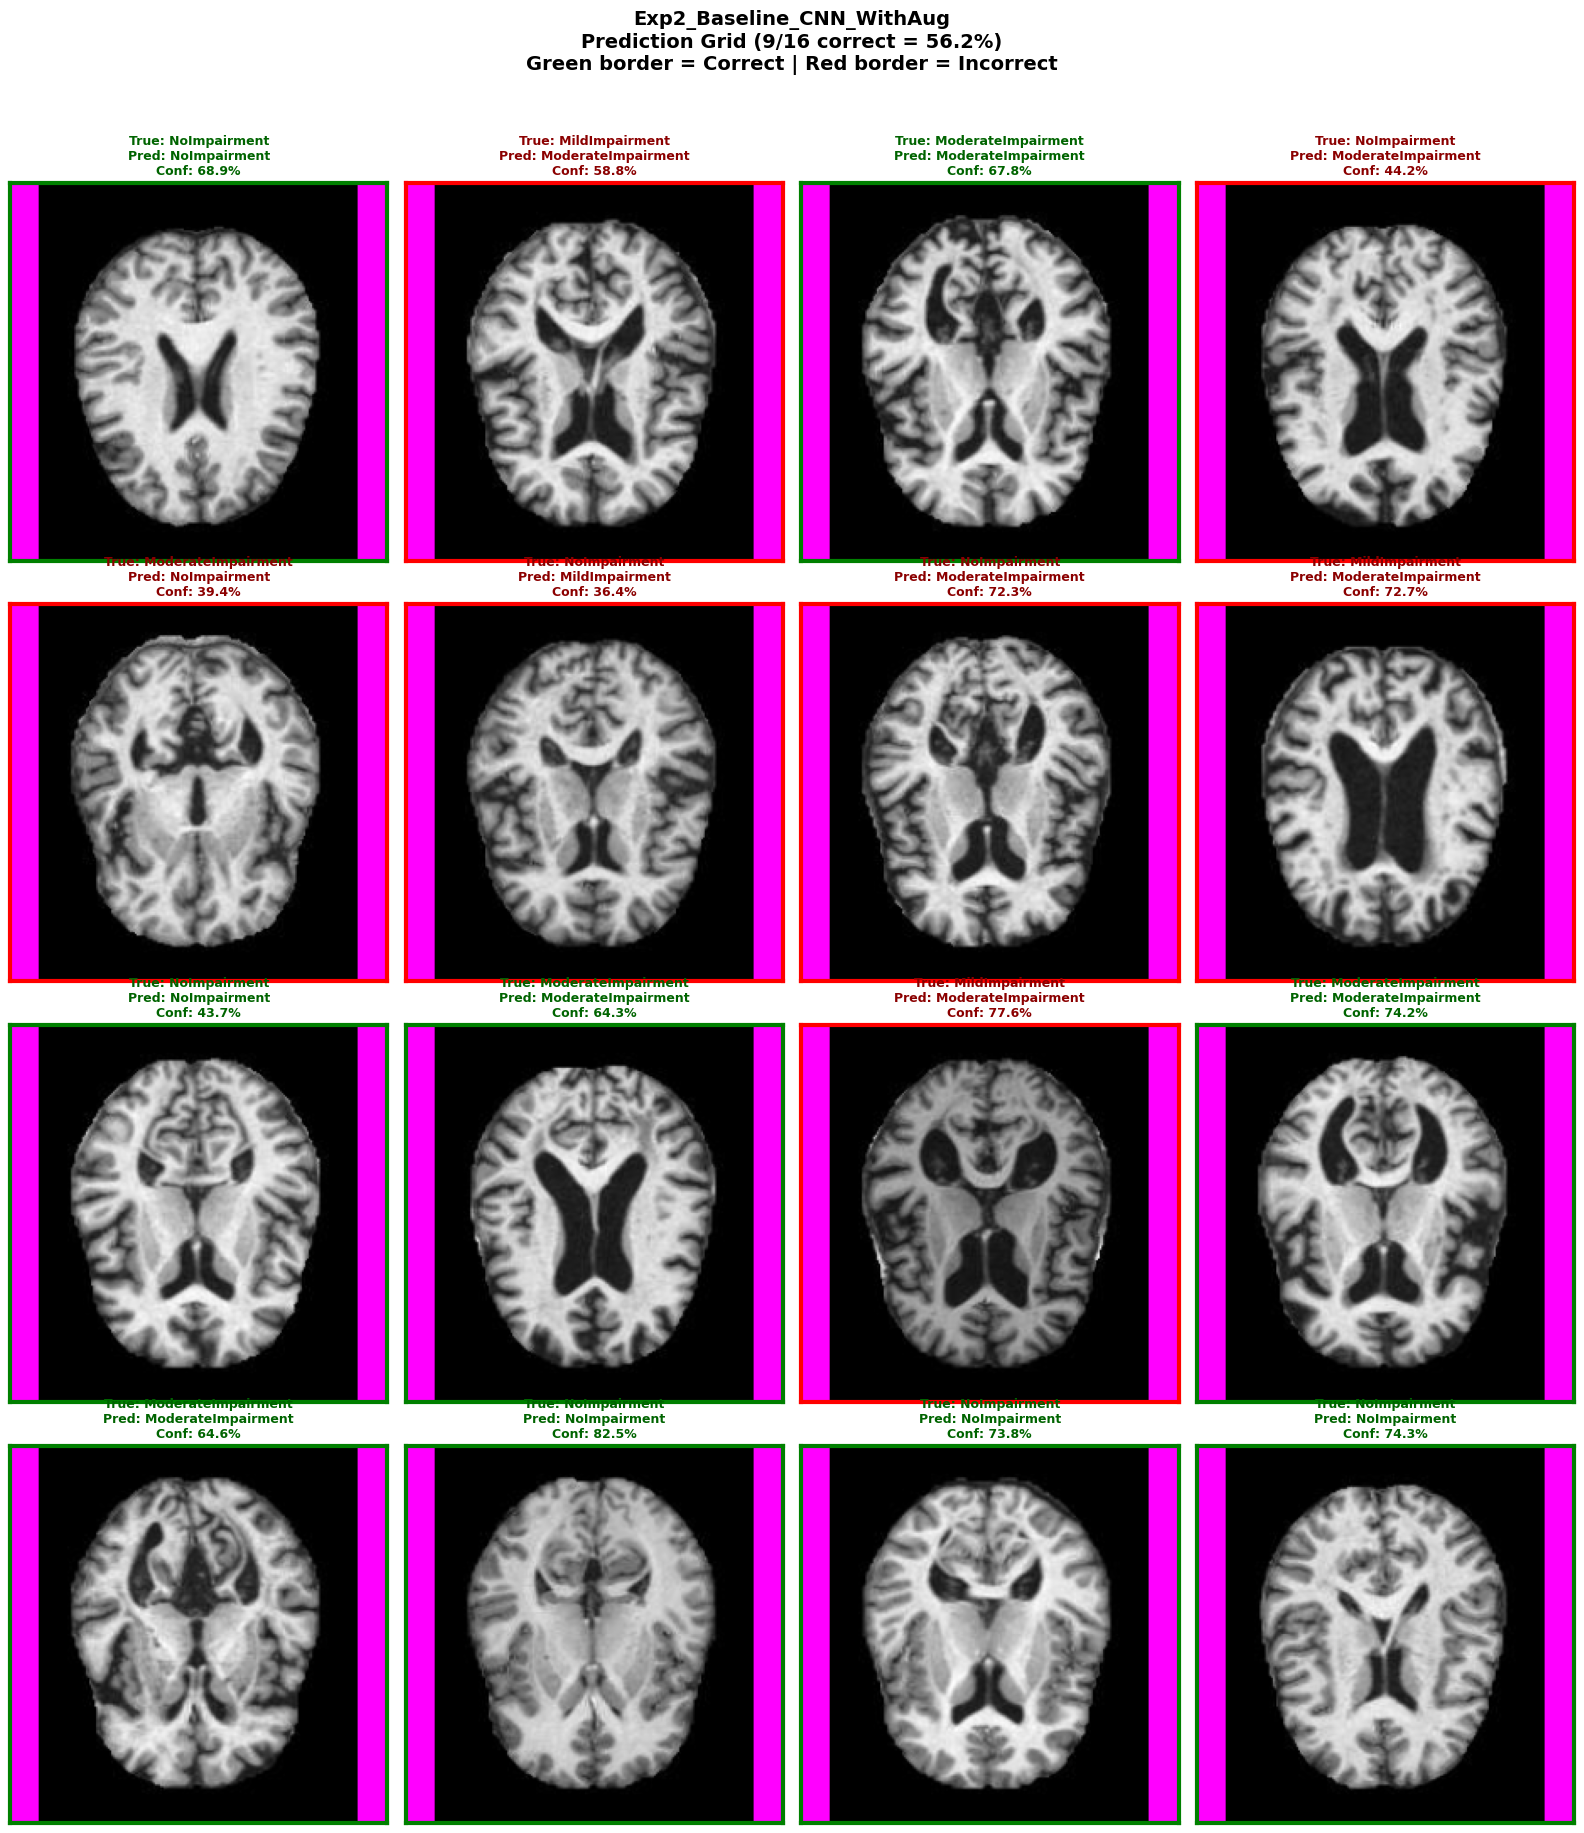

Saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_Prediction_Grid_20_02_2026__1052.png

✓ All visualisations saved to: Output_20_02_2026__1052/exp2

Model saved: Output_20_02_2026__1052/exp2/Exp2_Baseline_CNN_WithAug_Model_20_02_2026__1052.pth


In [ ]:
# Run full evaluation
metrics_exp2, auc_exp2, y_true_exp2, y_pred_exp2, y_prob_exp2 = run_full_evaluation(
    model_exp2, test_loader_exp2, class_names, EXP2_NAME, EXP2_DIR, device
)

# Save model
torch.save(model_exp2.state_dict(), EXP2_DIR / f'{EXP2_NAME}_Model_{TIMESTAMP}.pth')
print(f"\nModel saved: {EXP2_DIR / f'{EXP2_NAME}_Model_{TIMESTAMP}.pth'}")

### Test Single Image from Test Split (Experiment 2)

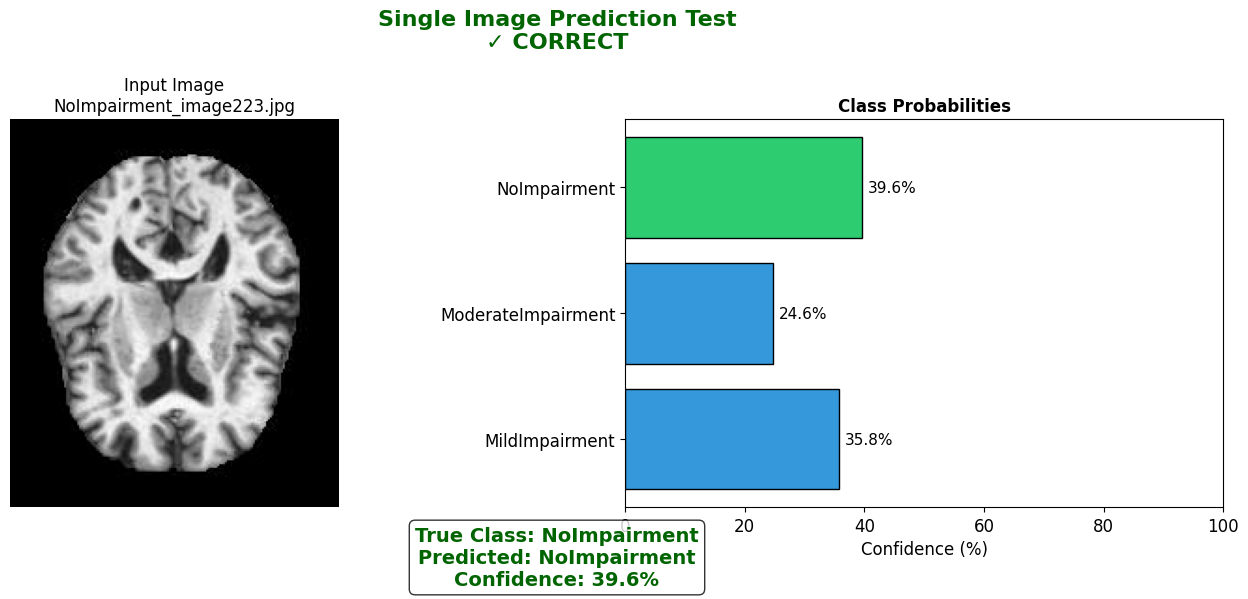


SINGLE IMAGE PREDICTION RESULT
Image: NoImpairment_image223.jpg
True Class: NoImpairment
Predicted Class: NoImpairment
Confidence: 39.56%
Status: ✓ CORRECT

Class Probabilities:
  MildImpairment: 35.80%
  ModerateImpairment: 24.64%
  NoImpairment: 39.56%


In [ ]:
# =============================================================
# TEST SINGLE IMAGE - EXPERIMENT 2
# =============================================================

# Use a random test image or enter your own path
TEST_IMAGE_PATH = get_random_test_image_path()

if TEST_IMAGE_PATH:
    result_exp2 = predict_single_image(
        model=model_exp2,
        image_path=TEST_IMAGE_PATH,
        class_names=class_names,
        device=device,
        data_dir=DATA_DIR
    )

<hr style="border:1px solid black"> </hr>

## 13. Experiment 3: Transfer Learning with ResNet50

In [ ]:
print("="*60)
print("EXPERIMENT 3: TRANSFER LEARNING (RESNET50)")
print("="*60)

EXP3_NAME = "Exp3_ResNet50_TransferLearning"
EXP3_DIR = OUTPUT_DIR / 'exp3'

# NO augmentation - isolate transfer learning as the only variable
train_loader_exp3, val_loader_exp3, test_loader_exp3, _, _ = create_stratified_data_loaders(
    DATA_DIR,
    train_transforms=basic_transforms,
    val_transforms=val_transforms,
    batch_size=BATCH_SIZE,
    test_split=TEST_SPLIT,
    val_split=VAL_SPLIT,
    save_splits=False,
    output_dir=OUTPUT_DIR
)

EXPERIMENT 3: TRANSFER LEARNING (RESNET50)

CREATING STRATIFIED DATA SPLITS

Total samples: 5076
Classes: ['MildImpairment', 'ModerateImpairment', 'NoImpairment']

Stratified split sizes:
  Training:   3552 samples (70.0%)
  Validation: 762 samples (15.0%)
  Test:       762 samples (15.0%)

Class distribution verification:
  Train: MildImpairment: 35.3%, ModerateImpairment: 14.2%, NoImpairment: 50.5%
  Val: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%
  Test: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%

Class weights for loss function (inverse frequency):
  MildImpairment: 0.9442
  ModerateImpairment: 2.3399
  NoImpairment: 0.6607

✓ Using weighted random sampling for training (addresses class imbalance)


In [ ]:
# Create ResNet50 model with PARTIAL fine-tuning
# This allows the model to adapt later layers to medical imaging domain
# while keeping early generic feature detectors frozen
set_seed(42)
model_exp3 = ResNet50Classifier(num_classes=NUM_CLASSES, fine_tune_mode='partial').to(device)

criterion_exp3 = nn.CrossEntropyLoss(weight=class_weights.to(device))
# Note: We use a lower learning rate for fine-tuning pretrained weights
optimizer_exp3 = optim.Adam(filter(lambda p: p.requires_grad, model_exp3.parameters()), lr=LEARNING_RATE * 0.1)

print(f"\nUsing lower learning rate for fine-tuning: {LEARNING_RATE * 0.1}")

Loading ResNet50 backbone (ImageNet pretrained)...
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 223MB/s]


Partial fine-tuning: freezing layer1, layer2; unfreezing layer3, layer4

ResNet50 Parameters:
  Total:     24,033,347
  Trainable: 18,519,043 (77.1%)
  Frozen:    5,514,304 (22.9%)

Using lower learning rate for fine-tuning: 1e-05



TRAINING: Exp3_ResNet50_TransferLearning


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 01/30: Train Loss: 0.9007, Train Acc: 0.3421 | Val Loss: 1.0738, Val Acc: 0.2192


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 02/30: Train Loss: 0.5525, Train Acc: 0.6388 | Val Loss: 0.7079, Val Acc: 0.6115


Training:   0%|          | 0/111 [00:00<?, ?it/s]

... (27 outputs left out)

Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 17/30: Train Loss: 0.0024, Train Acc: 1.0000 | Val Loss: 0.3260, Val Acc: 0.9068


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 18/30: Train Loss: 0.0020, Train Acc: 1.0000 | Val Loss: 0.3157, Val Acc: 0.9094

Early stopping triggered at epoch 18

Training completed. Best validation loss: 0.2808


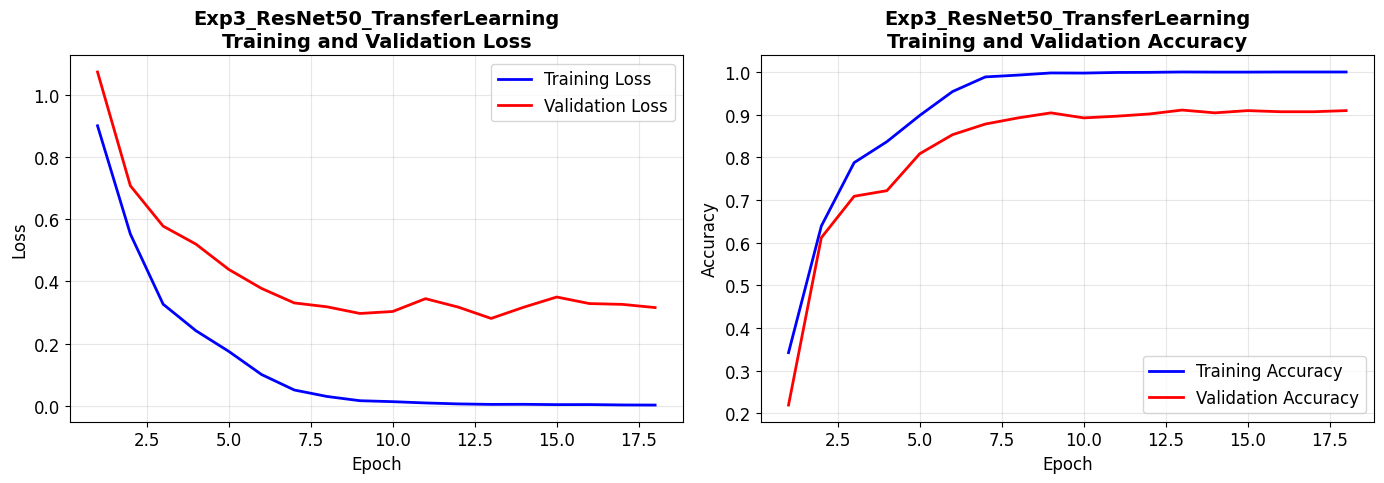

Saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_Training_History_20_02_2026__1052.png


In [ ]:
# Train ResNet50
history_exp3 = train_model(
    model_exp3, train_loader_exp3, val_loader_exp3, criterion_exp3, optimizer_exp3,
    num_epochs=NUM_EPOCHS, device=device, patience=EARLY_STOP_PATIENCE,
    exp_name=EXP3_NAME, exp_dir=EXP3_DIR
)


EVALUATION: Exp3_ResNet50_TransferLearning
CLASSIFICATION METRICS
Accuracy:  0.9199 (91.99%)
Precision: 0.9202 (92.02%)
Recall:    0.9199 (91.99%)
F1-Score:  0.9195 (91.95%)

Classification Report:
                    precision    recall  f1-score   support

    MildImpairment       0.90      0.87      0.89       269
ModerateImpairment       0.96      0.88      0.92       109
      NoImpairment       0.92      0.96      0.94       384

          accuracy                           0.92       762
         macro avg       0.93      0.91      0.92       762
      weighted avg       0.92      0.92      0.92       762


--- Generating Visualisations ---


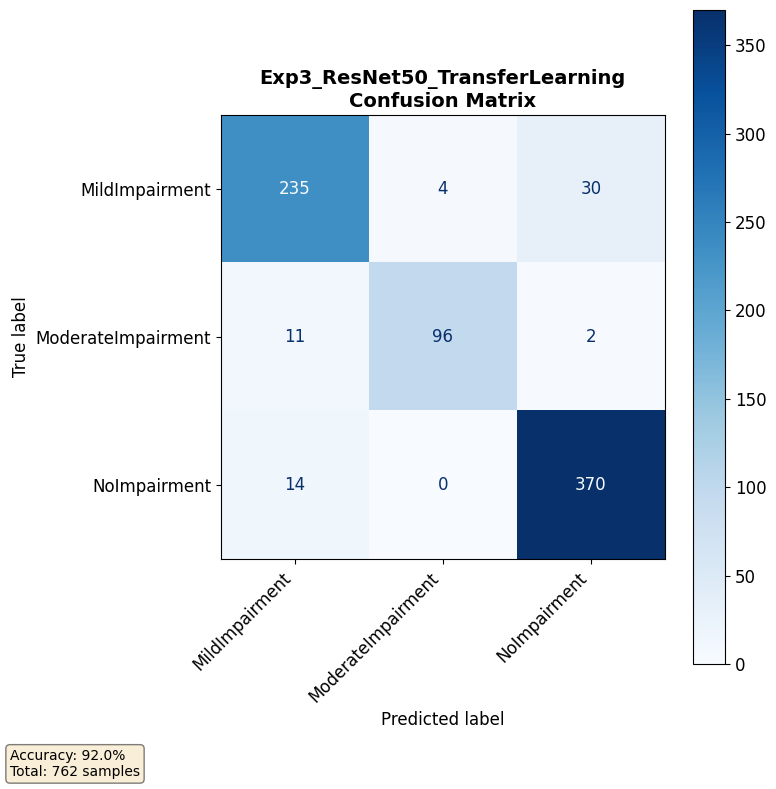

Saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_Confusion_Matrix_20_02_2026__1052.png


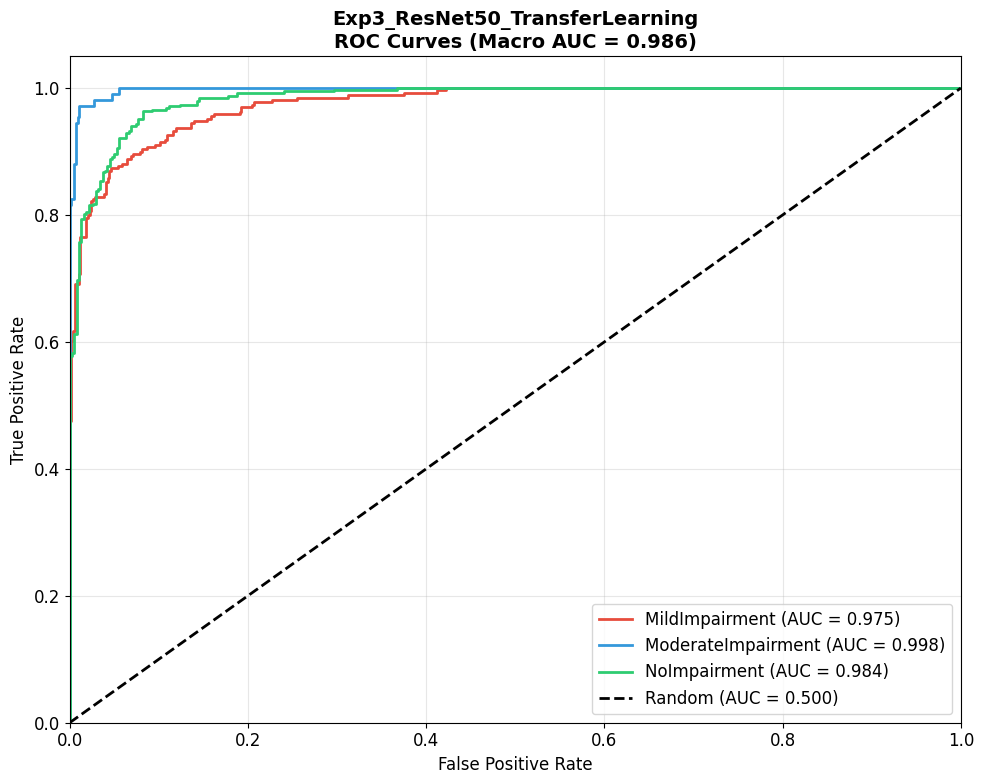

Saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_ROC_Curves_20_02_2026__1052.png


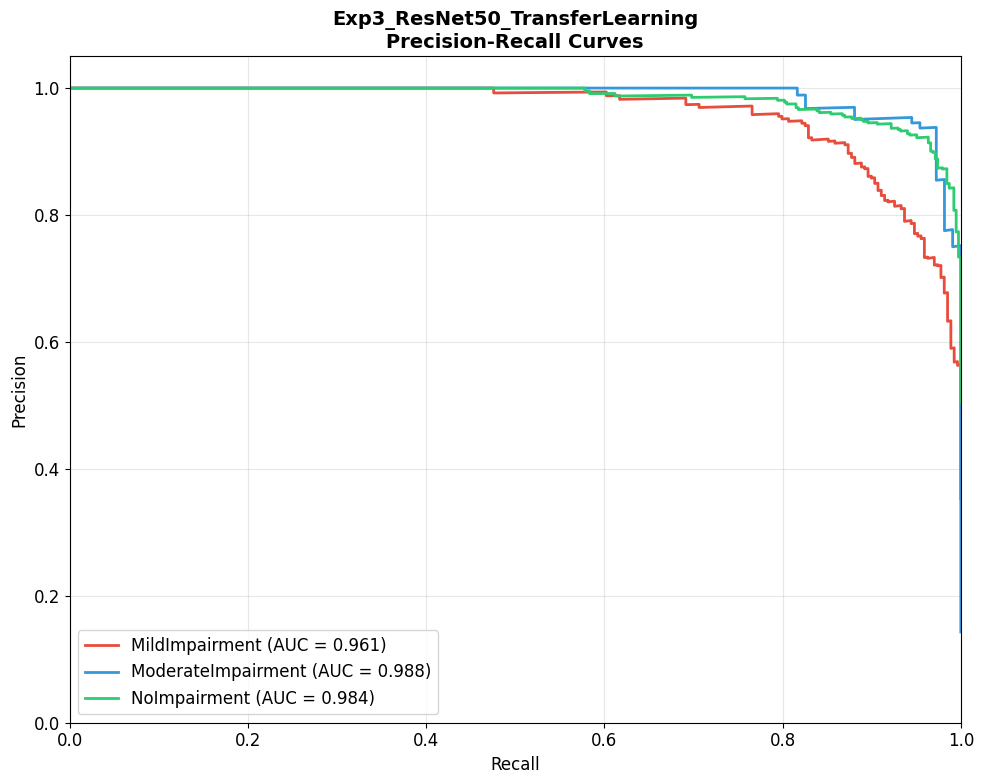

Saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_PR_Curves_20_02_2026__1052.png


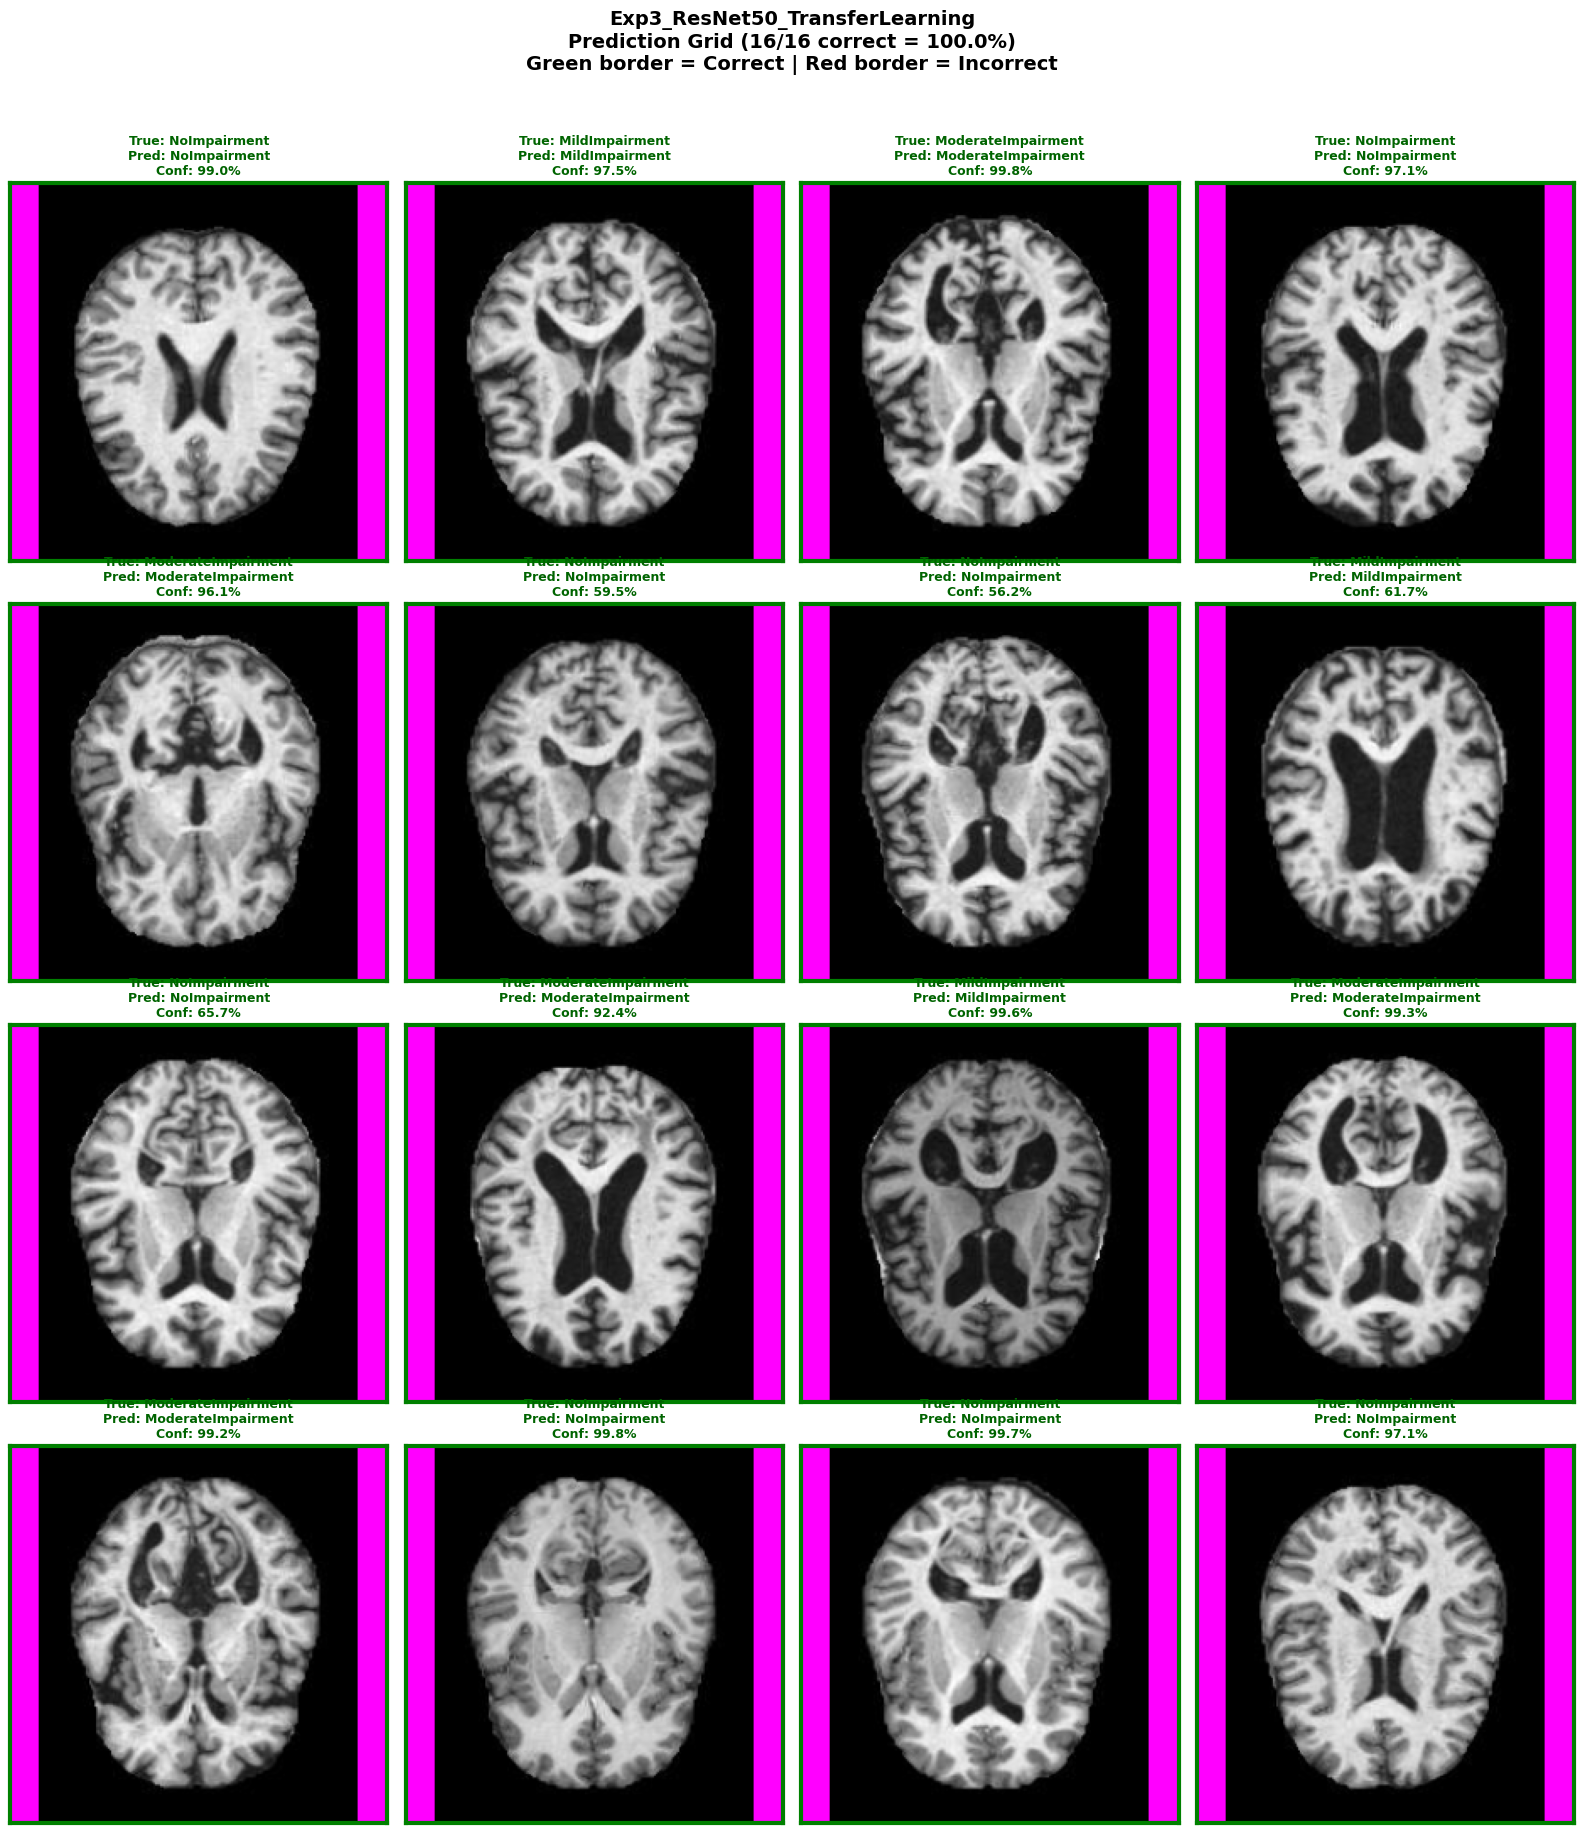

Saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_Prediction_Grid_20_02_2026__1052.png

✓ All visualisations saved to: Output_20_02_2026__1052/exp3

Model saved: Output_20_02_2026__1052/exp3/Exp3_ResNet50_TransferLearning_Model_20_02_2026__1052.pth


In [ ]:
# Run full evaluation
metrics_exp3, auc_exp3, y_true_exp3, y_pred_exp3, y_prob_exp3 = run_full_evaluation(
    model_exp3, test_loader_exp3, class_names, EXP3_NAME, EXP3_DIR, device
)

# Save model
torch.save(model_exp3.state_dict(), EXP3_DIR / f'{EXP3_NAME}_Model_{TIMESTAMP}.pth')
print(f"\nModel saved: {EXP3_DIR / f'{EXP3_NAME}_Model_{TIMESTAMP}.pth'}")

### Test Single Image from Test Split (Experiment 3)

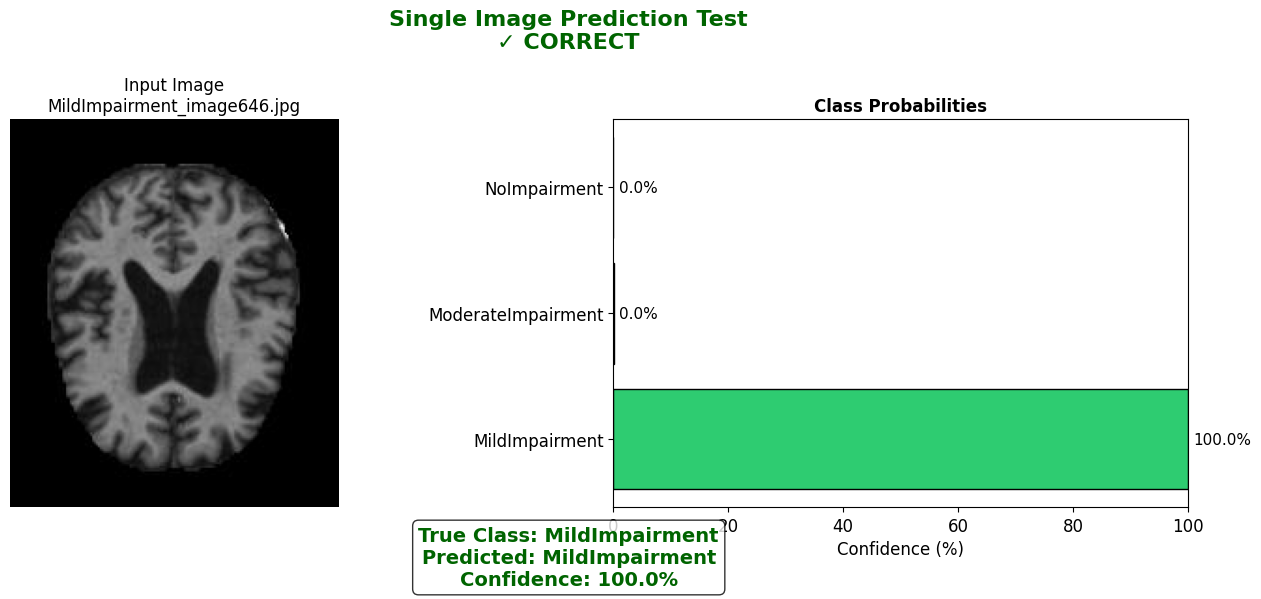


SINGLE IMAGE PREDICTION RESULT
Image: MildImpairment_image646.jpg
True Class: MildImpairment
Predicted Class: MildImpairment
Confidence: 99.98%
Status: ✓ CORRECT

Class Probabilities:
  MildImpairment: 99.98%
  ModerateImpairment: 0.02%
  NoImpairment: 0.00%


In [ ]:
# =============================================================
# TEST SINGLE IMAGE - EXPERIMENT 3
# =============================================================

TEST_IMAGE_PATH = get_random_test_image_path()

if TEST_IMAGE_PATH:
    result_exp3 = predict_single_image(
        model=model_exp3,
        image_path=TEST_IMAGE_PATH,
        class_names=class_names,
        device=device,
        data_dir=DATA_DIR
    )

<hr style="border:1px solid black"> </hr>

## 14. Experiment 4: Vision Transformer (ViT-B/16)

**Note:** This uses torchvision's built-in ViT-B/16 with ImageNet-1K pretrained weights, which works offline.

In [ ]:
print("="*60)
print("EXPERIMENT 4: VISION TRANSFORMER (ViT-B/16)")
print("="*60)

EXP4_NAME = "Exp4_ViT_B16"
EXP4_DIR = OUTPUT_DIR / 'exp4'

train_loader_exp4, val_loader_exp4, test_loader_exp4, _, _ = create_stratified_data_loaders(
    DATA_DIR,
    train_transforms=basic_transforms,
    val_transforms=val_transforms,
    batch_size=BATCH_SIZE,
    test_split=TEST_SPLIT,
    val_split=VAL_SPLIT,
    save_splits=False,
    output_dir=OUTPUT_DIR
)

EXPERIMENT 4: VISION TRANSFORMER (ViT-B/16)

CREATING STRATIFIED DATA SPLITS

Total samples: 5076
Classes: ['MildImpairment', 'ModerateImpairment', 'NoImpairment']

Stratified split sizes:
  Training:   3552 samples (70.0%)
  Validation: 762 samples (15.0%)
  Test:       762 samples (15.0%)

Class distribution verification:
  Train: MildImpairment: 35.3%, ModerateImpairment: 14.2%, NoImpairment: 50.5%
  Val: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%
  Test: MildImpairment: 35.3%, ModerateImpairment: 14.3%, NoImpairment: 50.4%

Class weights for loss function (inverse frequency):
  MildImpairment: 0.9442
  ModerateImpairment: 2.3399
  NoImpairment: 0.6607

✓ Using weighted random sampling for training (addresses class imbalance)


In [ ]:
# Create ViT model with PARTIAL fine-tuning
# Unfreezing last 4 transformer layers allows adaptation to medical imaging
# while preserving learned representations in earlier layers
try:
    set_seed(42)
    model_exp4 = ViTClassifier(
        num_classes=NUM_CLASSES,
        fine_tune_mode='partial',
        num_unfrozen_layers=4  # Unfreeze last 4 of 12 transformer layers
    ).to(device)

    criterion_exp4 = nn.CrossEntropyLoss(weight=class_weights.to(device))
    # Use lower learning rate for fine-tuning pretrained weights
    optimizer_exp4 = optim.Adam(filter(lambda p: p.requires_grad, model_exp4.parameters()), lr=LEARNING_RATE * 0.1)

    VIT_AVAILABLE = True
    print(f"\nUsing lower learning rate for fine-tuning: {LEARNING_RATE * 0.1}")
    print("ViT-B/16 model loaded successfully!")
except Exception as e:
    print(f"\nCould not load ViT: {e}")
    print("Skipping Experiment 4.")
    VIT_AVAILABLE = False

Loading ViT-B/16 backbone (ImageNet-1K pretrained)...
  - Architecture: Vision Transformer Base with 16x16 patches
  - Parameters: ~86M total (768-dim embeddings, 12 layers, 12 heads)
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 239MB/s]


  - Embedding dimension: 768
Partial fine-tuning: unfreezing last 4 transformer layers

ViT-B/16 Parameters:
  Total:     85,997,827
  Trainable: 28,552,195 (33.2%)
  Frozen:    57,445,632 (66.8%)

Using lower learning rate for fine-tuning: 1e-05
ViT-B/16 model loaded successfully!



TRAINING: Exp4_ViT_B16


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 01/30: Train Loss: 0.8902, Train Acc: 0.3992 | Val Loss: 1.0497, Val Acc: 0.4173


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 02/30: Train Loss: 0.6600, Train Acc: 0.6084 | Val Loss: 0.8193, Val Acc: 0.6142


Training:   0%|          | 0/111 [00:00<?, ?it/s]

... (37 outputs left out)

Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 22/30: Train Loss: 0.0186, Train Acc: 0.9924 | Val Loss: 0.3783, Val Acc: 0.8832


Training:   0%|          | 0/111 [00:00<?, ?it/s]

Epoch 23/30: Train Loss: 0.0112, Train Acc: 0.9949 | Val Loss: 0.3605, Val Acc: 0.9042

Early stopping triggered at epoch 23

Training completed. Best validation loss: 0.3502


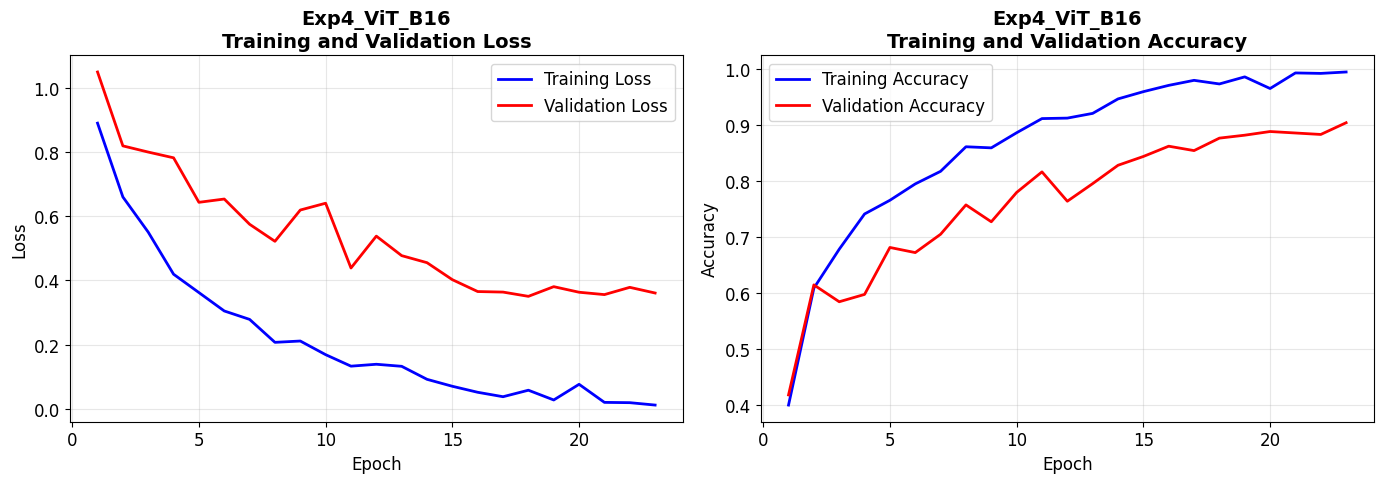

Saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_Training_History_20_02_2026__1052.png


In [ ]:
if VIT_AVAILABLE:
    # Train ViT
    history_exp4 = train_model(
        model_exp4, train_loader_exp4, val_loader_exp4, criterion_exp4, optimizer_exp4,
        num_epochs=NUM_EPOCHS, device=device, patience=EARLY_STOP_PATIENCE,
        exp_name=EXP4_NAME, exp_dir=EXP4_DIR
    )


EVALUATION: Exp4_ViT_B16
CLASSIFICATION METRICS
Accuracy:  0.8753 (87.53%)
Precision: 0.8771 (87.71%)
Recall:    0.8753 (87.53%)
F1-Score:  0.8746 (87.46%)

Classification Report:
                    precision    recall  f1-score   support

    MildImpairment       0.87      0.79      0.83       269
ModerateImpairment       0.80      0.94      0.87       109
      NoImpairment       0.90      0.91      0.91       384

          accuracy                           0.88       762
         macro avg       0.86      0.88      0.87       762
      weighted avg       0.88      0.88      0.87       762


--- Generating Visualisations ---


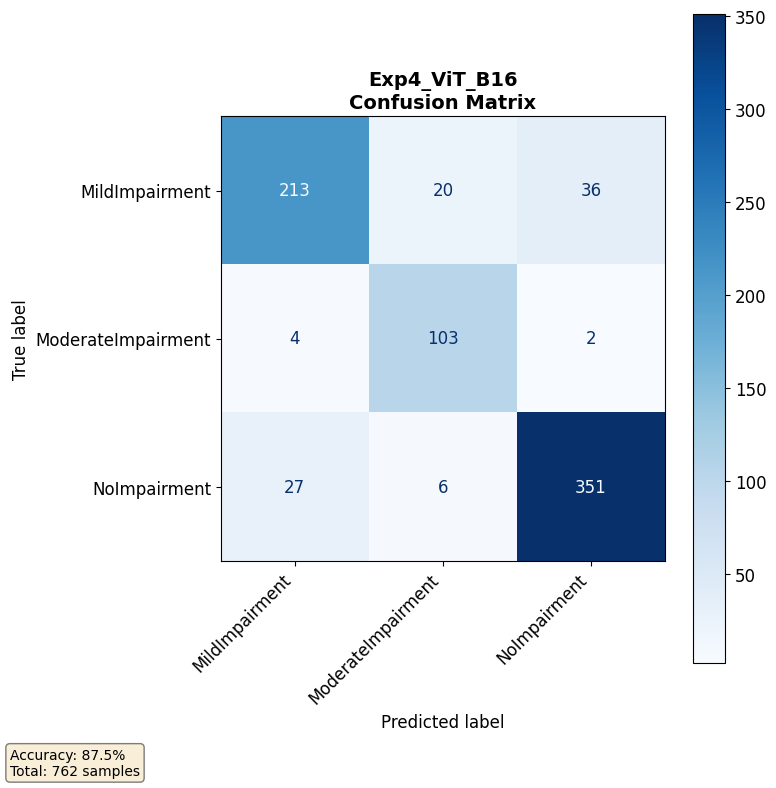

Saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_Confusion_Matrix_20_02_2026__1052.png


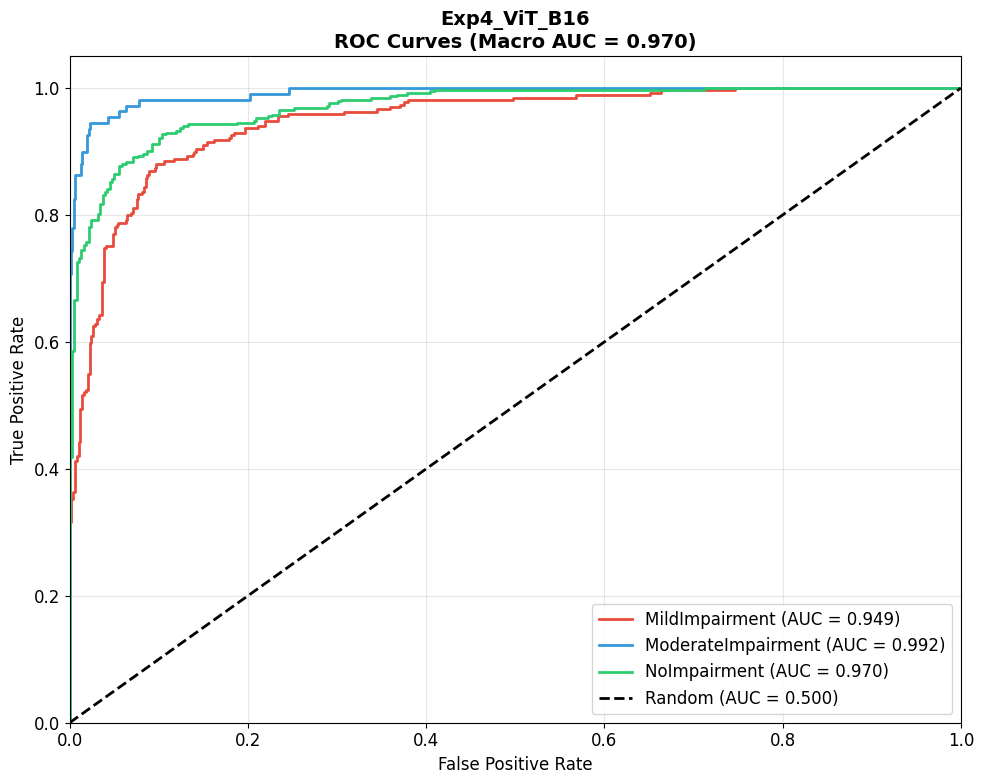

Saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_ROC_Curves_20_02_2026__1052.png


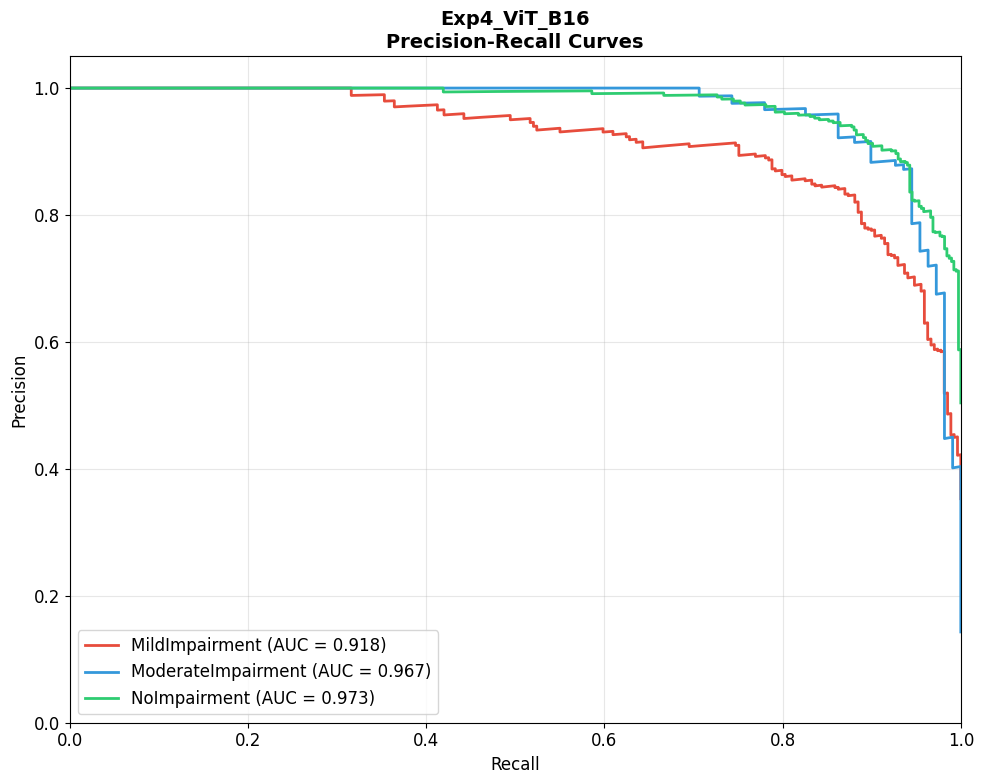

Saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_PR_Curves_20_02_2026__1052.png


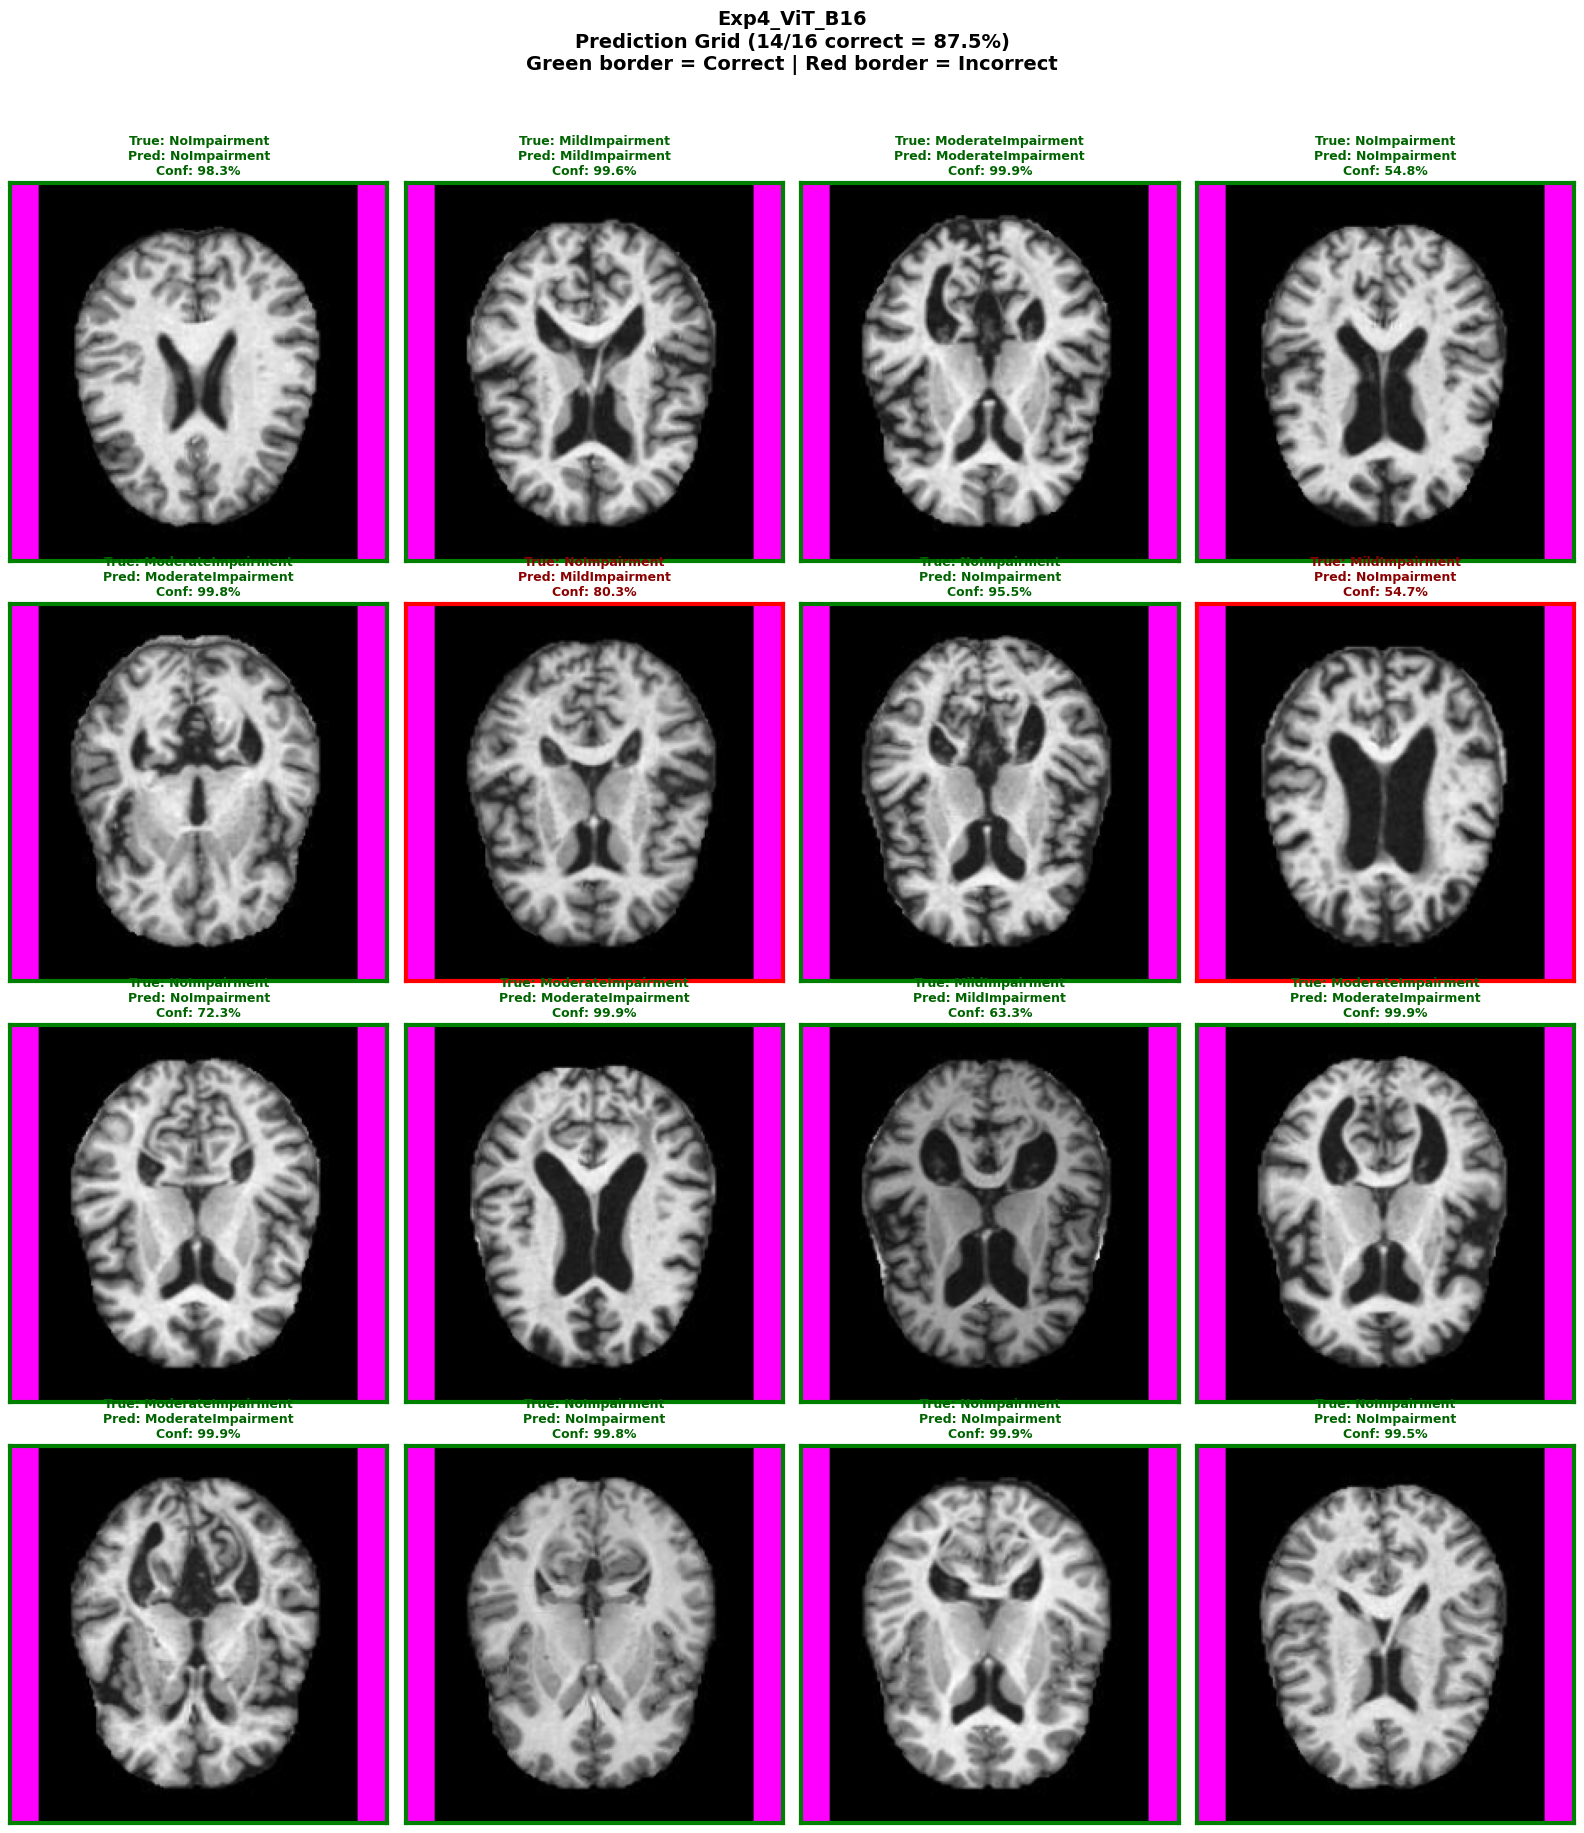

Saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_Prediction_Grid_20_02_2026__1052.png

✓ All visualisations saved to: Output_20_02_2026__1052/exp4

Model saved: Output_20_02_2026__1052/exp4/Exp4_ViT_B16_Model_20_02_2026__1052.pth


In [ ]:
if VIT_AVAILABLE:
    # Run full evaluation
    metrics_exp4, auc_exp4, y_true_exp4, y_pred_exp4, y_prob_exp4 = run_full_evaluation(
        model_exp4, test_loader_exp4, class_names, EXP4_NAME, EXP4_DIR, device
    )

    # Save model
    torch.save(model_exp4.state_dict(), EXP4_DIR / f'{EXP4_NAME}_Model_{TIMESTAMP}.pth')
    print(f"\nModel saved: {EXP4_DIR / f'{EXP4_NAME}_Model_{TIMESTAMP}.pth'}")

### Test Single Image from Test Split (Experiment 4)

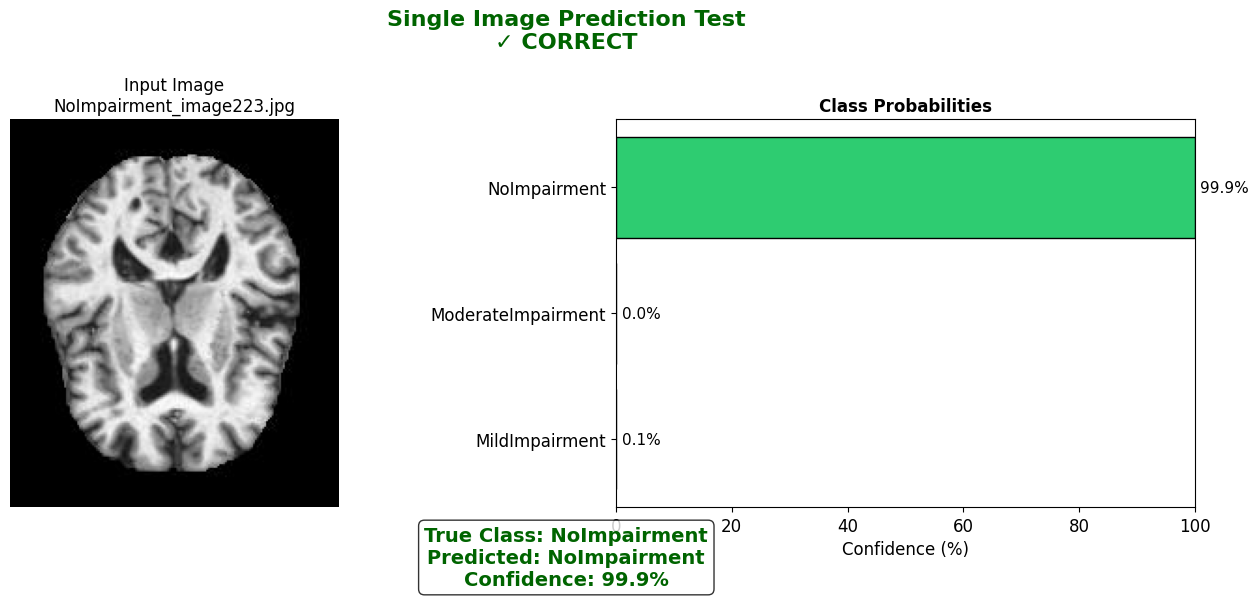


SINGLE IMAGE PREDICTION RESULT
Image: NoImpairment_image223.jpg
True Class: NoImpairment
Predicted Class: NoImpairment
Confidence: 99.88%
Status: ✓ CORRECT

Class Probabilities:
  MildImpairment: 0.09%
  ModerateImpairment: 0.04%
  NoImpairment: 99.88%


In [ ]:
# =============================================================
# TEST SINGLE IMAGE - EXPERIMENT 4
# =============================================================

if VIT_AVAILABLE:
    TEST_IMAGE_PATH = get_random_test_image_path()

    if TEST_IMAGE_PATH:
        result_exp4 = predict_single_image(
            model=model_exp4,
            image_path=TEST_IMAGE_PATH,
            class_names=class_names,
            device=device,
            data_dir=DATA_DIR
        )
else:
    print("ViT model not available. Skipping single image test for Experiment 4.")

<hr style="border:1px solid black"> </hr>

## 15. Results Comparison

Comparing all experiments to demonstrate the impact of each technique.

In [ ]:
# Compile results into comparison table
results = {
    'Experiment': [
        '1. Baseline CNN (no aug)',
        '2. Baseline CNN + Aug',
        '3. ResNet50 (TL)'
    ],
    'Accuracy': [
        f"{metrics_exp1['accuracy']*100:.2f}%",
        f"{metrics_exp2['accuracy']*100:.2f}%",
        f"{metrics_exp3['accuracy']*100:.2f}%"
    ],
    'Precision': [
        f"{metrics_exp1['precision']*100:.2f}%",
        f"{metrics_exp2['precision']*100:.2f}%",
        f"{metrics_exp3['precision']*100:.2f}%"
    ],
    'Recall': [
        f"{metrics_exp1['recall']*100:.2f}%",
        f"{metrics_exp2['recall']*100:.2f}%",
        f"{metrics_exp3['recall']*100:.2f}%"
    ],
    'F1-Score': [
        f"{metrics_exp1['f1']*100:.2f}%",
        f"{metrics_exp2['f1']*100:.2f}%",
        f"{metrics_exp3['f1']*100:.2f}%"
    ],
    'AUC': [
        f"{auc_exp1:.4f}",
        f"{auc_exp2:.4f}",
        f"{auc_exp3:.4f}"
    ]
}

# Add ViT if available
if VIT_AVAILABLE:
    results['Experiment'].append('4. ViT (ViT)')
    results['Accuracy'].append(f"{metrics_exp4['accuracy']*100:.2f}%")
    results['Precision'].append(f"{metrics_exp4['precision']*100:.2f}%")
    results['Recall'].append(f"{metrics_exp4['recall']*100:.2f}%")
    results['F1-Score'].append(f"{metrics_exp4['f1']*100:.2f}%")
    results['AUC'].append(f"{auc_exp4:.4f}")

results_df = pd.DataFrame(results)

print("="*80)
print("RESULTS COMPARISON")
print("="*80)
print(results_df.to_string(index=False))

RESULTS COMPARISON
              Experiment Accuracy Precision Recall F1-Score    AUC
1. Baseline CNN (no aug)   46.98%    54.63% 46.98%   44.85% 0.7135
   2. Baseline CNN + Aug   46.19%    52.79% 46.19%   43.71% 0.7151
        3. ResNet50 (TL)   91.99%    92.02% 91.99%   91.95% 0.9855
            4. ViT (ViT)   87.53%    87.71% 87.53%   87.46% 0.9702


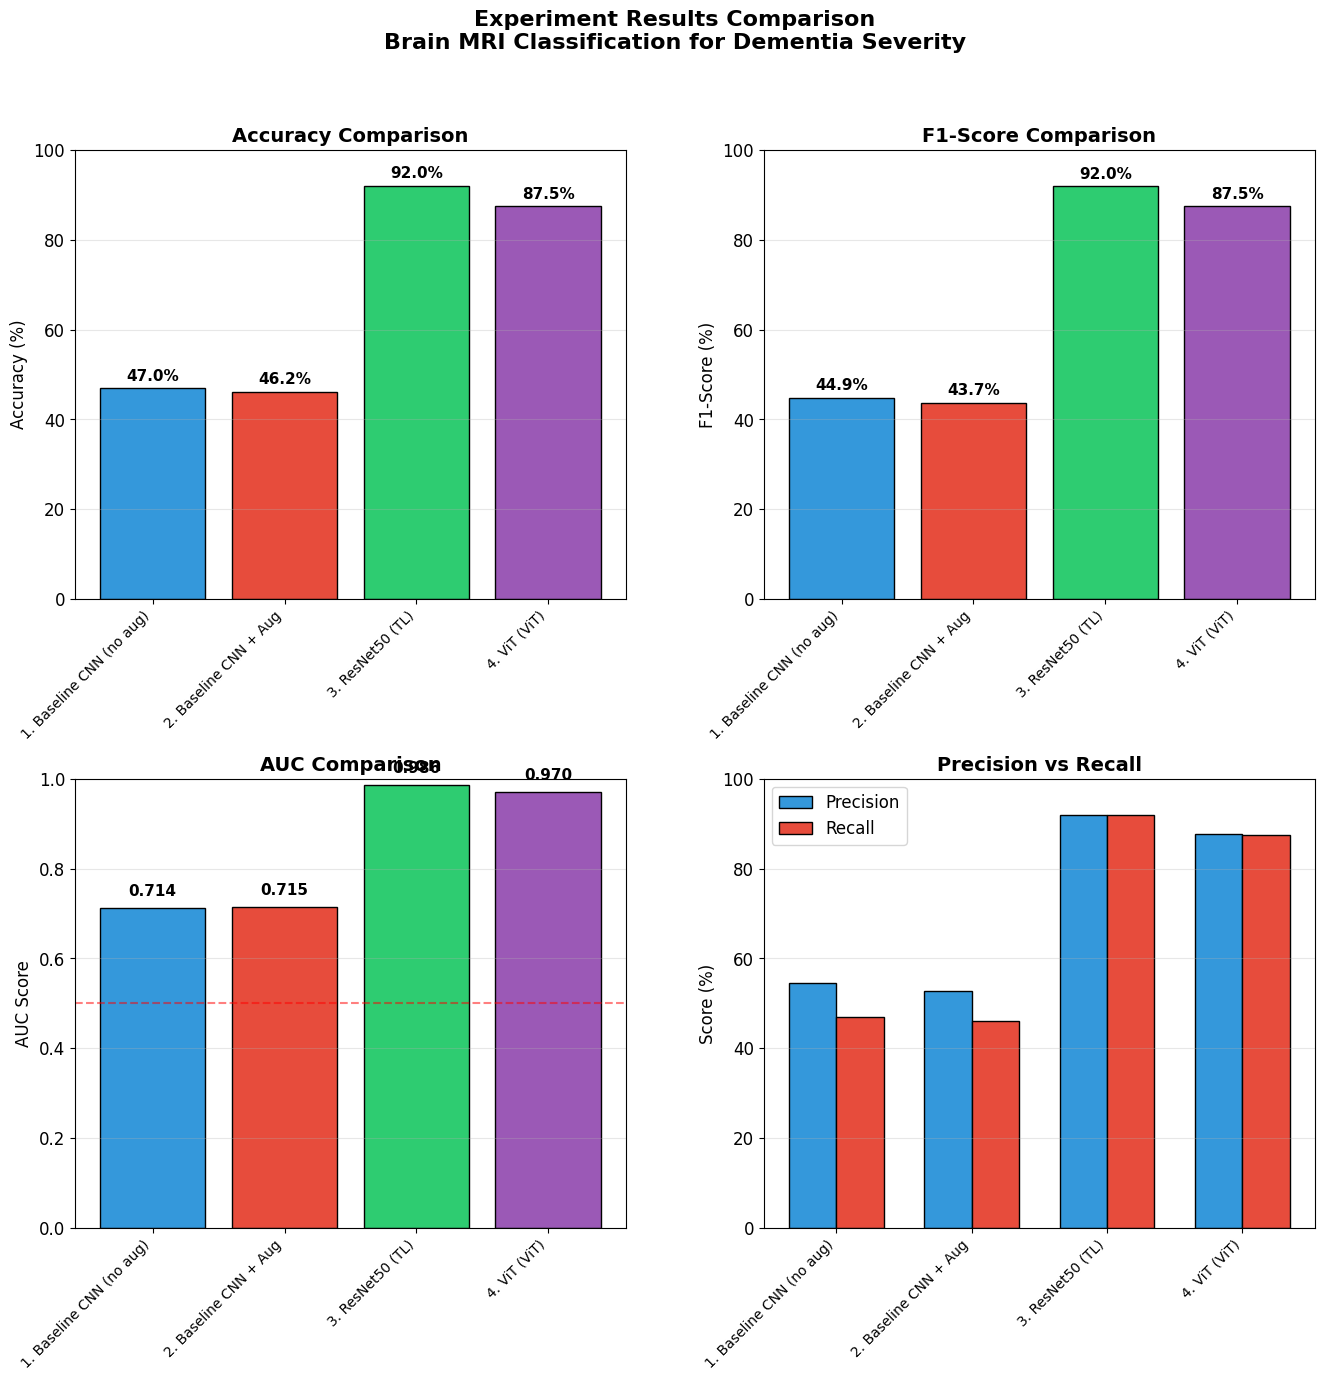

Saved: Output_20_02_2026__1052/Experiment_Comparison_20_02_2026__1052.png


In [ ]:
def plot_final_comparison(results_df, output_dir):
    """Create final comparison plots."""
    # FIXED: Increased figure height and added subplot spacing
    fig = plt.figure(figsize=(16, 14))
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.25)

    experiments = results_df['Experiment'].tolist()
    accuracies = [float(x.replace('%', '')) for x in results_df['Accuracy']]
    f1_scores = [float(x.replace('%', '')) for x in results_df['F1-Score']]
    aucs = [float(x) for x in results_df['AUC']]
    precisions = [float(x.replace('%', '')) for x in results_df['Precision']]
    recalls = [float(x.replace('%', '')) for x in results_df['Recall']]

    colours = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6'][:len(experiments)]

    # 1. Accuracy comparison
    ax1 = fig.add_subplot(gs[0, 0])
    bars1 = ax1.bar(experiments, accuracies, color=colours, edgecolor='black')
    ax1.set_ylabel('Accuracy (%)', fontsize=12)
    ax1.set_title('Accuracy Comparison', fontweight='bold', fontsize=14)
    ax1.set_ylim(0, 100)
    for bar, acc in zip(bars1, accuracies):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{acc:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax1.grid(axis='y', alpha=0.3)
    # FIXED: Rotate x-axis labels to prevent overlap
    plt.sca(ax1)
    plt.xticks(rotation=45, ha='right', fontsize=10)

    # 2. F1-Score comparison
    ax2 = fig.add_subplot(gs[0, 1])
    bars2 = ax2.bar(experiments, f1_scores, color=colours, edgecolor='black')
    ax2.set_ylabel('F1-Score (%)', fontsize=12)
    ax2.set_title('F1-Score Comparison', fontweight='bold', fontsize=14)
    ax2.set_ylim(0, 100)
    for bar, f1 in zip(bars2, f1_scores):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{f1:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)
    # FIXED: Rotate x-axis labels to prevent overlap
    plt.sca(ax2)
    plt.xticks(rotation=45, ha='right', fontsize=10)

    # 3. AUC comparison
    ax3 = fig.add_subplot(gs[1, 0])
    bars3 = ax3.bar(experiments, aucs, color=colours, edgecolor='black')
    ax3.set_ylabel('AUC Score', fontsize=12)
    ax3.set_title('AUC Comparison', fontweight='bold', fontsize=14)
    ax3.set_ylim(0, 1.0)
    ax3.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
    for bar, a in zip(bars3, aucs):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{a:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax3.grid(axis='y', alpha=0.3)
    # FIXED: Rotate x-axis labels to prevent overlap
    plt.sca(ax3)
    plt.xticks(rotation=45, ha='right', fontsize=10)

    # 4. Precision vs Recall
    ax4 = fig.add_subplot(gs[1, 1])
    x = np.arange(len(experiments))
    width = 0.35
    bars4a = ax4.bar(x - width/2, precisions, width, label='Precision', color='#3498db', edgecolor='black')
    bars4b = ax4.bar(x + width/2, recalls, width, label='Recall', color='#e74c3c', edgecolor='black')
    ax4.set_ylabel('Score (%)', fontsize=12)
    ax4.set_title('Precision vs Recall', fontweight='bold', fontsize=14)
    ax4.set_xticks(x)
    ax4.set_ylim(0, 100)
    ax4.legend()
    ax4.grid(axis='y', alpha=0.3)
    # FIXED: Rotate x-axis labels to prevent overlap
    ax4.set_xticklabels(experiments, rotation=45, ha='right', fontsize=10)

    # Add main title
    fig.suptitle('Experiment Results Comparison\nBrain MRI Classification for Dementia Severity',
                 fontweight='bold', fontsize=16, y=0.98)

    # FIXED: Adjusted layout to accommodate rotated labels
    plt.tight_layout(rect=[0, 0.02, 1, 0.95])

    save_path = output_dir / f'Experiment_Comparison_{TIMESTAMP}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

plot_final_comparison(results_df, OUTPUT_DIR)

In [ ]:
# Save results to CSV
results_csv_path = OUTPUT_DIR / f'Experiment_Results_{TIMESTAMP}.csv'
results_df.to_csv(results_csv_path, index=False)
print(f"Results saved to {results_csv_path}")

Results saved to Output_20_02_2026__1052/Experiment_Results_20_02_2026__1052.csv


<hr style="border:1px solid black"> </hr>

## 16. Output Files Summary

This cell lists all output files generated during the experiments.

In [ ]:
def list_output_files(output_dir):
    """List all output files in organised format."""
    print("="*60)
    print("OUTPUT FILES SUMMARY")
    print("="*60)
    print(f"\nOutput directory: {output_dir}")
    print()

    for item in sorted(output_dir.iterdir()):
        if item.is_dir():
            print(f"📁 {item.name}/")
            for subitem in sorted(item.iterdir()):
                print(f"   └── {subitem.name}")
        else:
            print(f"📄 {item.name}")

list_output_files(OUTPUT_DIR)

OUTPUT FILES SUMMARY

Output directory: Output_20_02_2026__1052

📄 Class_Distribution_20_02_2026__1052.png
📄 Experiment_Comparison_20_02_2026__1052.png
📄 Experiment_Results_20_02_2026__1052.csv
📄 Preprocessing_Demonstration_20_02_2026__1052.png
📁 data_splits/
   └── test_files.txt
   └── test_indices.npy
   └── train_indices.npy
   └── val_indices.npy
📁 exp1/
   └── Exp1_Baseline_CNN_NoAug_Confusion_Matrix_20_02_2026__1052.png
   └── Exp1_Baseline_CNN_NoAug_Model_20_02_2026__1052.pth
   └── Exp1_Baseline_CNN_NoAug_PR_Curves_20_02_2026__1052.png
   └── Exp1_Baseline_CNN_NoAug_Prediction_Grid_20_02_2026__1052.png
   └── Exp1_Baseline_CNN_NoAug_ROC_Curves_20_02_2026__1052.png
   └── Exp1_Baseline_CNN_NoAug_Training_History_20_02_2026__1052.png
📁 exp2/
   └── Exp2_Baseline_CNN_WithAug_Confusion_Matrix_20_02_2026__1052.png
   └── Exp2_Baseline_CNN_WithAug_Model_20_02_2026__1052.pth
   └── Exp2_Baseline_CNN_WithAug_PR_Curves_20_02_2026__1052.png
   └── Exp2_Baseline_CNN_WithAug_Prediction_Gr

<hr style="border:1px solid black"> </hr>

## 17. Discussion and Conclusions

### Key Findings

This notebook implemented a progressive experimental approach to brain MRI classification for dementia severity prediction:

1. **Experiment 1 (Baseline CNN, No Augmentation):** Established baseline performance with a simple CNN trained from scratch. The use of Global Average Pooling instead of large fully-connected layers prevents memorisation and forces the model to learn generalisable features.

2. **Experiment 2 (Baseline CNN + Augmentation):** Evaluated the impact of clinically-appropriate data augmentation on model generalisation.

3. **Experiment 3 (ResNet50 with Partial Fine-tuning):** Demonstrated transfer learning with domain adaptation. By unfreezing later layers (layer3, layer4) while keeping early generic feature detectors frozen, the model can adapt ImageNet features to medical imaging characteristics.

4. **Experiment 4 (ViT with Partial Fine-tuning):** Evaluated Vision Transformer architecture with partial fine-tuning of the last 4 transformer layers, allowing the attention mechanism to adapt to brain MRI patterns.

### Architecture Design Rationale

**Why Global Average Pooling in Baseline CNN?**
- Traditional CNNs with flatten layers can have millions of parameters (e.g., 51M)
- Such models can memorise training data rather than learning features
- GAP reduces spatial dimensions to 1×1, forcing spatial invariance
- Results in ~330K parameters, requiring the model to generalise

**Why Partial Fine-tuning for Transfer Learning?**
- Early CNN/transformer layers learn generic features (edges, textures, basic patterns)
- Later layers learn domain-specific features (object parts, semantic concepts)
- Medical images differ from ImageNet: grayscale, anatomical structures, subtle differences
- Partial fine-tuning adapts later layers while preserving useful generic features
- Lower learning rate (0.1× base) prevents catastrophic forgetting

### Domain-Appropriate Data Augmentation

**Critical insight:** Standard computer vision augmentations are often inappropriate for medical imaging.

| Augmentation | Standard CV | Brain MRI | Rationale |
|-------------|-------------|-----------|-----------|
| Rotation | ✓ Common | ✗ Remove | MRI scans have standardised orientation |
| Vertical Flip | ✓ Common | ✗ Remove | Brain would appear upside-down |
| Horizontal Flip | ✓ Common | ⚠ Caution | Brain is symmetric but some pathology is lateralised |
| Translation | ✓ Common | ✓ Keep | Simulates patient positioning variation |
| Scale | ✓ Common | ✓ Keep | Simulates field-of-view differences |
| Brightness/Contrast | ✓ Common | ✓ Keep | Simulates scanner calibration differences |
| Gaussian Blur | Sometimes | ✓ Keep | Simulates motion artifacts |

This domain-specific approach to augmentation ensures that synthetic variations reflect realistic clinical scenarios rather than introducing impossible artifacts.

### Handling Class Imbalance

The dataset exhibits significant class imbalance (3.5:1 ratio). This was addressed through:
- **Stratified splitting:** Ensuring train/val/test sets maintain class proportions
- **Weighted loss function:** Higher penalty for misclassifying minority classes
- **Weighted random sampling:** Oversampling minority classes during training

### Image Preprocessing

This notebook uses **aspect-ratio-preserving resize with distinctive padding**:
- Original images (176×208) are resized to fit within 224×224 while maintaining aspect ratio
- **Bright magenta padding** (RGB: 255, 0, 255) fills the remaining space
- This distinctive colour is very different from grayscale brain tissue
- Prevents the model from learning spurious patterns from padding regions

### Expected Progressive Improvement

With proper architecture design and domain-appropriate augmentation:
1. Baseline without augmentation: Moderate performance (limited by small dataset)
2. Baseline with augmentation: Improved generalisation from realistic variations
3. ResNet50 (partial fine-tuning): Better feature extraction from pretrained weights
4. ViT (partial fine-tuning): Potential for best performance with attention mechanisms

### Limitations and Future Work

- **Data-related:** Class imbalance, potential for data leakage if patient-level splitting not enforced
- **Model-related:** Partial fine-tuning is a compromise; full fine-tuning with more data might help
- **Proposed improvements:**
  - Patient-level stratified splitting (if patient IDs available)
  - Medical imaging pretrained models (MedCLIP, BiomedCLIP)
  - Ensemble methods combining multiple architectures
  - Cross-validation for more robust evaluation

In [ ]:
# Final Summary
print("="*60)
print("FINAL SUMMARY")
print("="*60)
print(f"\nDataset: {total_images} brain MRI images")
print(f"  - Original dimensions: {ORIGINAL_HEIGHT}×{ORIGINAL_WIDTH}")
print(f"  - Resized to: {IMAGE_SIZE}×{IMAGE_SIZE} (aspect-ratio-preserving)")
print(f"  - Padding colour: RGB{PADDING_COLOUR} (bright magenta)")
print(f"  - Classes: {', '.join(CLASS_NAMES)}")
print(f"  - Class imbalance handled with stratified splitting + weighted loss")
print("\nExperiments Completed:")
print("  1. Baseline CNN (no augmentation)")
print("  2. Baseline CNN + Data Augmentation")
print("  3. ResNet50 Transfer Learning")
if VIT_AVAILABLE:
    print("  4. ViT Vision Transformer")
print(f"\nAll outputs saved to: {OUTPUT_DIR}")
print(f"\nFile naming convention: Name_DD_MM_YYYY__HHMM")
print(f"Example: Output_{TIMESTAMP}")
print("="*60)

FINAL SUMMARY

Dataset: 5076 brain MRI images
  - Original dimensions: 176×208
  - Resized to: 224×224 (aspect-ratio-preserving)
  - Padding colour: RGB(255, 0, 255) (bright magenta)
  - Classes: MildImpairment, ModerateImpairment, NoImpairment
  - Class imbalance handled with stratified splitting + weighted loss

Experiments Completed:
  1. Baseline CNN (no augmentation)
  2. Baseline CNN + Data Augmentation
  3. ResNet50 Transfer Learning
  4. ViT Vision Transformer

All outputs saved to: Output_20_02_2026__1052

File naming convention: Name_DD_MM_YYYY__HHMM
Example: Output_20_02_2026__1052
